# 11 · Summary statistics from skewers through TNG50-4

The summary statistics of notebook 10, measured on skewers through the TNG50-4 snapshot 25 instead of the toy boxes:
the density on the skewers, the transmission and the overflux, and the 3D, isotropic, wedge, P1D, $\xi_{\rm 1D}$ and
decomposition statistics, with the same functions and figures. The simulation path (the snapshot, its cells and the
deposition) is explained in notebooks 05 and 07, the statistics of the cells of the same snapshot in notebook 09; the
statistics on skewers, their bins and conventions in notebook 10. Four lines (`LINE_IDS`: $\mathrm{Ly}\alpha$, Si III 1206, Si II 1193,
Si II 1190), and the BAO scale $r_d$ of the simulation's cosmology, which a box of $L = 51.7$ cMpc sees only through its
periodic images.

- **Part A — skewers:** a regular lattice of skewers along each axis of the box, periodic, in the snapshot frame.
- **Part B — the density on the skewers,** against the density of the whole box through a mesh.
- **Part C — transmission and overflux.**
- **Part D — summary statistics of the overfluxes:** D1 bins and statistics, D2 planes, D3 $P$, $r^2\xi$ and wedges,
  D4 P1D next to DESI DR1, D5 by order, D6 term by term.

One simulation has no independent realisations: the three lines of sight $x$, $y$, $z$ are the ensemble (points with
error bars: the mean over the three and its error), correlated through the same gas.

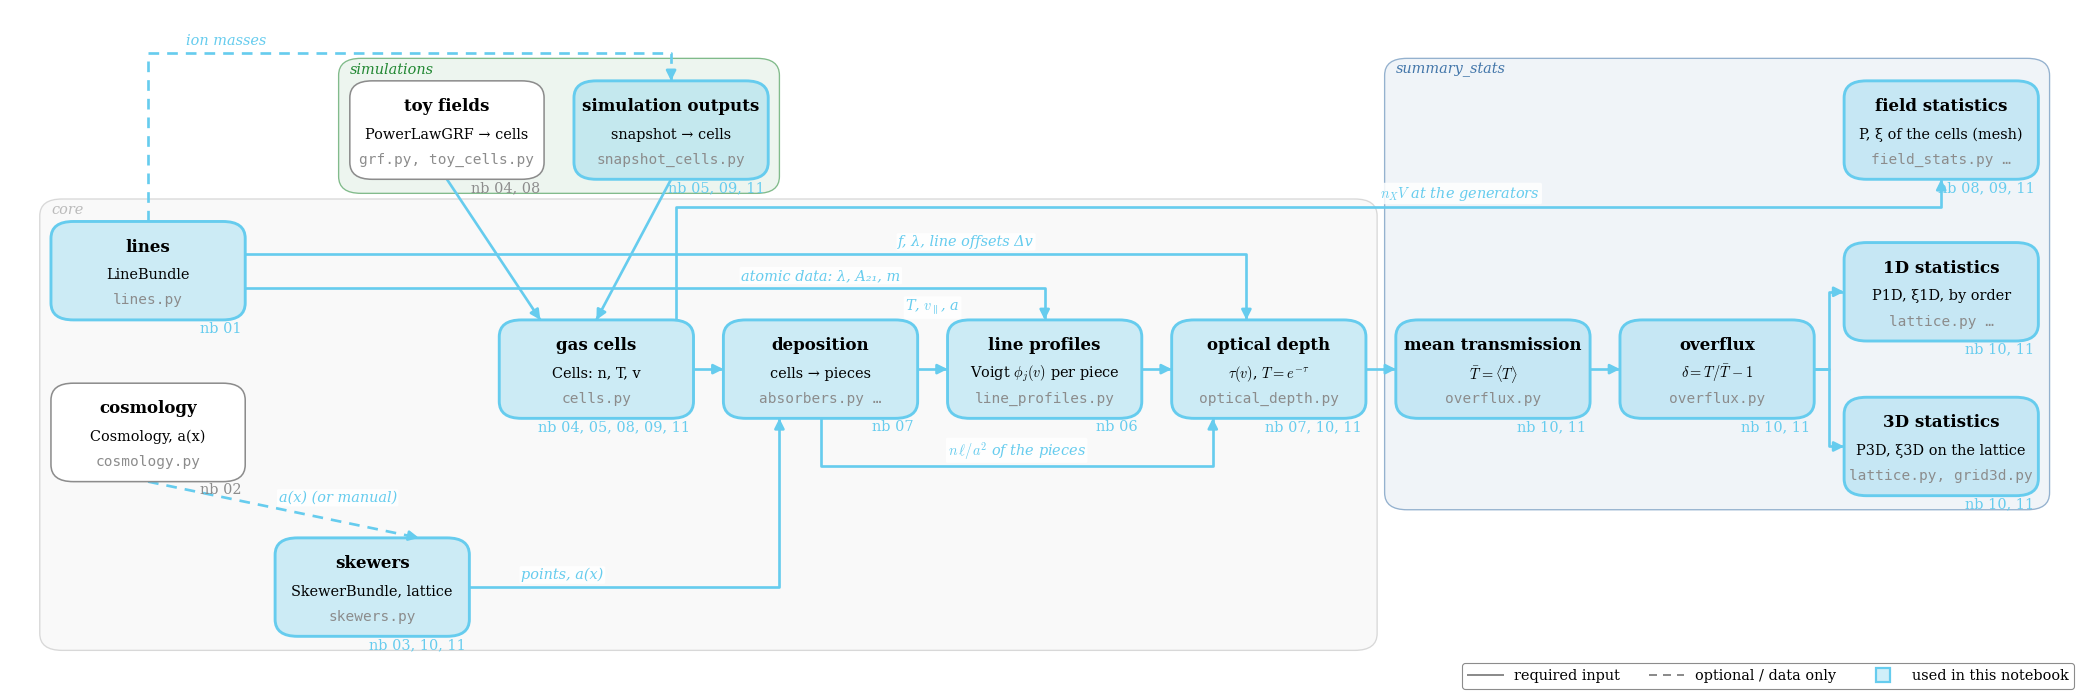

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import time, warnings
import numpy as np, jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)          # SkewerJAX follows this flag; it never sets it itself
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import use_style, use_backend
# use_backend()                                    # interactive figures in a live notebook
use_style()
from skewerjax.utils.plotting import add_panel_letters, plot_dag
from skewerjax.core import LineBundle, phys
from skewerjax.utils.paths import DATA_DIR as DATA      # folder with TNG50-4/: $SKEWERJAX_DATA (docs/installation.md)
plot_dag(("lines", "skewers", "simulation", "fields", "profiles", "deposition", "tau", "normalisation", "overflux", "stats_1d",
          "stats_3d", "field_stats")); plt.show()

In [2]:
from skewerjax.simulations import ArepoHDF5Reader
reader = ArepoHDF5Reader(f"{DATA}/TNG50-4", 25)          # the snapshot of notebooks 05 and 07
H = reader.header
L = H.box_cMpc                                           # the box [cMpc]
LINE_IDS = ("HI-LyA", "SiIII-1206", "SiII-1193", "SiII-1190")   # the lines: every statistic and figure follows them
LINES = LineBundle(list(LINE_IDS), ref_line_id=LINE_IDS[0])   # as in 10: line 1, the reference, Lyα
AXES = (1, 2, 3)                   # the lines of sight x, y, z: the ensemble of the statistics
N_SK = 32                          # skewers per transverse axis: N_SK^2 per line of sight, L / N_SK apart
SPACING_KMS = 0.5                  # a point of the paths every 0.5 km/s of Hubble flow: pieces W <= 0.5 km/s (resolution check, Part A)
N_PIX, BATCH = 256, 256            # velocity pixels over one period; skewers per call (memory only)
DETUNING = "linear"                # as 10: the first-order frequency offset of the profiles (changes tau by < 1e-5)
HUBBLE_FLOW = "linear"             # the snapshot frame is linear by construction ((aH)_snap y): "exact" gives the same line centres
A_EFF = None                       # not needed: in the snapshot frame every piece is at the snapshot's a (a_eff = a changes nothing)
MEAN = "redshift"                  # T_bar(z); one snapshot: every pixel at the same a, so the global mean (checked in Part C)
N_MESH, MAS, INTERLACE = 256, "pcs", True   # the full-box density of Part B: cells through a mesh (Sefusatti et al. 2016)
ENSEMBLE = "3 lines of sight (not independent)"
EACH = "each of the " + ENSEMBLE  # the legend of the faint curves
u = H.velfac_kms_per_cMpc          # aH [km/s per cMpc]: v = u x
print(f"TNG50-4 snapshot 25: z = {H.redshift:.4f}, a = {H.a:.5f}, box L = {L:.3f} cMpc, {H.n_gas:,} gas cells")
print(f"u = aH = {u:.3f} km/s per cMpc, v_per = u L = {u * L:.1f} km/s (H.vmax_kms = {H.vmax_kms:.1f})")
from skewerjax.core import sound_horizon_drag
from skewerjax.simulations import TNG_COSMOLOGY as TNG
from skewerjax.utils.plotting import fold_periodic
R_BAO = float(sound_horizon_drag(TNG["Omega_b"] * H.h**2, H.omega_m * H.h**2))  # r_d [Mpc] (Aubourg et al. 2015, eq. 16): the BAO scale, comoving
n_img = np.arange(-4, 5)
print(f"r_BAO = r_d = {R_BAO:.2f} cMpc = {R_BAO / L:.3f} L (L = {L:.2f} cMpc): on the line of sight its images sit at |r_d - n L| folded into "
      f"[0, L / 2]: {np.unique(np.round(fold_periodic(R_BAO - n_img * L, L), 2))} cMpc (notebook 09)")

TNG50-4 snapshot 25: z = 3.0081, a = 0.24949, box L = 51.668 cMpc, 19,250,411 gas cells
u = aH = 76.673 km/s per cMpc, v_per = u L = 3961.5 km/s (H.vmax_kms = 3961.5)
r_BAO = r_d = 147.30 cMpc = 2.851 L (L = 51.67 cMpc): on the line of sight its images sit at |r_d - n L| folded into [0, L / 2]: [7.71] cMpc (notebook 09)


## Part A — Skewers

Along each axis, $N_{\rm SK}^2$ straight skewers through the whole box on a regular transverse lattice, $L/N_{\rm SK}$
apart (the nodes $i\,L/N_{\rm SK}$ of the two other axes), from 0 to $L$: the first and last points are the same place
of the periodic box, so every skewer is periodic along the line of sight and the samples form the lattice of 10's
3D statistics. `SimulationSkewers.axis_aligned` gives the points and the snapshot frame; every cell of the snapshot is
read once (`select_cells_in_region`, `gas_to_cells`, the default `ExtractionOptions` of 05 and 07: H I stored, Si III
and Si II from CLOUDY), and `cell_pieces` and `compute_optical_depth` run as in 10.

In [3]:
from skewerjax.simulations import SimulationSkewers, gas_to_cells, select_cells_in_region
from skewerjax.core import velocity_span
from skewerjax.core import lattice_columns
from skewerjax.summary_stats import lattice_limits
t0 = time.perf_counter()
GAS = select_cells_in_region(reader, 0.0, L)                   # every cell of the snapshot (GasCells)
CELLS = gas_to_cells(GAS, LINES.species_keys)                  # -> core.Cells: per species n (comoving), T, v
t_read = time.perf_counter() - t0
COLS = lattice_columns(N_SK, (1, 1))                           # (N_SK^2, 2) the transverse indices (i_a, i_b), a-major
D_PERP = L / N_SK                                              # the transverse spacing [cMpc]
TRANSVERSE = {1: (1, 2), 2: (0, 2), 3: (0, 1)}                 # the transverse axes (a, b) of each line of sight


def cofm(axis, cols):
    # a point of each skewer [code units]: the transverse nodes (i_a, i_b) D_PERP
    p = np.zeros((len(cols), 3))
    a, b = TRANSVERSE[axis]
    p[:, a], p[:, b] = cols[:, 0] * D_PERP, cols[:, 1] * D_PERP
    return p / H.code_length_cMpc


SK0 = SimulationSkewers.axis_aligned(reader, cofm(1, COLS[:1]), [1], SPACING_KMS, cells=GAS)   # one skewer: the geometry
FRAME = SK0.frame("snapshot")                                  # one a, linear Hubble flow
PERIOD = float(velocity_span(FRAME, HUBBLE_FLOW)[0])           # v_per [km/s]: (aH)_snap L
N_LOS = SK0.points.shape[1] - 1                                # points along a skewer, the end point (= the first) dropped
DS = L / N_LOS                                                 # their spacing [cMpc]
V = (np.arange(N_PIX) + 0.5) * PERIOD / N_PIX                  # the velocity grid: N_PIX pixel centres over the period (Lyα axis)
DV = PERIOD / N_PIX
lim = lattice_limits(L, D_PERP, N_PIX, PERIOD)                 # the lattice of Part D
print(f"{len(CELLS):,} cells read and turned into core.Cells in {t_read:.1f} s; sizes V^(1/3) from {CELLS.size_cMpc.min():.3f} "
      f"to {CELLS.size_cMpc.max():.2f} cMpc (median {np.median(CELLS.size_cMpc):.3f})")
print(f"skewers: {N_SK} x {N_SK} = {len(COLS)} per line of sight, {D_PERP:.4f} cMpc apart; {len(AXES) * len(COLS)} in all")
print(f"points: {N_LOS} per skewer, every {DS * 1e3:.2f} ckpc = {DS * u:.3f} km/s; v_per = {PERIOD:.2f} km/s "
      f"(= u L: {abs(PERIOD / (u * L) - 1):.0e}); pixels: {N_PIX} of dv = {DV:.2f} km/s, P1D up to pi / dv = {np.pi / DV:.4f} s/km")

19,250,411 cells read and turned into core.Cells in 12.8 s; sizes V^(1/3) from 0.000 to 0.46 cMpc (median 0.160)
skewers: 32 x 32 = 1024 per line of sight, 1.6146 cMpc apart; 3072 in all
points: 7923 per skewer, every 6.52 ckpc = 0.500 km/s; v_per = 3961.55 km/s (= u L: 0e+00); pixels: 256 of dv = 15.47 km/s, P1D up to pi / dv = 0.2030 s/km


**$\tau$, axis by axis.** For every batch of skewers: the pieces of the cells (`cell_pieces`) and $\tau$ of the
lines of `LINE_IDS` on the $\mathrm{Ly}\alpha$ axis (`compute_optical_depth`, every option in the call), and the density at the points
(the column of each point's dual segment over its length, the end point merged with the first).

In [4]:
from tqdm.auto import tqdm
from skewerjax.core import compute_optical_depth
from skewerjax.core.absorbers import cell_pieces
from skewerjax.summary_stats import on_lattice

TAU, DENS, RES, T_AX = [], [], [], []      # tau (N_lines, N_sk, N_PIX) per axis, the density at the points, resolution checks, timings
t0 = time.perf_counter()
bar = tqdm(total=len(AXES) * len(COLS), desc="skewers")
with warnings.catch_warnings(record=True) as WARN:                     # the resolution check of compute_optical_depth (counted below)
    warnings.simplefilter("always")
    for axis in AXES:
        t_p = t_t = 0.0
        tau_a, dens_a = [], {sp: [] for sp in LINES.species_keys}
        for b in range(0, len(COLS), BATCH):
            t1 = time.perf_counter()
            cols_b = COLS[b:b + BATCH]
            sk = SimulationSkewers.axis_aligned(reader, cofm(axis, cols_b), np.full(len(cols_b), axis), SPACING_KMS, cells=GAS)
            pieces, parts = cell_pieces(CELLS, LINES, points=sk.points, frame=sk.frame("snapshot"), a_data=H.a, return_parts=True)
            seg, near = parts["segments"], parts["cells"]                # the dual segments and the cells they index
            for sp, d in dens_a.items():                                 # sum_p n_p l_p over each dual segment (SimulationSkewers.point_values)
                n_c = np.asarray(near.species[sp]["number_density"])
                col = np.where(seg.cell >= 0, seg.weight * n_c[np.maximum(seg.cell, 0)] * seg.length, 0.0).sum(-1)
                col[:, 0] += col[:, -1]                                  # the first and last points: one dual segment
                d.append(col[:, :-1] / DS)                               # its mean density [comoving cm^-3]
            t2 = time.perf_counter()
            tau_b, info = compute_optical_depth(  # CALCULATION OF THE OPTICAL DEPTH tau
                pieces, V, LINES, line_frame="reference", velocity_period=True, voigt="ExoJAX", detuning=DETUNING,
                hubble_flow=HUBBLE_FLOW, aH_ref=None, a_eff=A_EFF, resolution_tolerance=0.25, return_info=True
            )
            tau_a.append(np.asarray(tau_b))
            RES.append(np.stack([info["resolution"]["max_ratio"], info["resolution"]["column_fraction"]], -1))
            t_p, t_t = t_p + t2 - t1, t_t + time.perf_counter() - t2
            bar.update(len(cols_b))
        TAU.append(np.concatenate(tau_a, axis=1))
        DENS.append({sp: on_lattice(np.concatenate(d), N_SK, N_SK) for sp, d in dens_a.items()})   # (N_SK, N_LOS, N_SK)
        T_AX.append((t_p, t_t))
bar.close()
TAU, T_AX, RES = np.stack(TAU), np.array(T_AX), np.array(RES)          # TAU (3, N_lines, N_sk, N_PIX)
t_skewers = time.perf_counter() - t0
del GAS, SK0, sk, pieces, parts, seg, near

skewers:   0%|          | 0/3072 [00:00<?, ?it/s]

In [5]:
from skewerjax.utils.plotting import line_names
NAMES_L = line_names(LINE_IDS)                                  # Lyα, Si III, Si II 1193, Si II 1190
n_ax, n_sk = TAU.shape[0], TAU.shape[2]
b_1e4 = {lid: np.sqrt(2 * phys.kB * 1e4 / m) / 1e3 for lid, m in zip(LINE_IDS, np.asarray(LINES.mass_amu))}
print(f"{n_ax} lines of sight x {n_sk} skewers in {t_skewers:.0f} s; per axis: pieces {T_AX[:, 0].mean():.0f} s, tau {T_AX[:, 1].mean():.0f} s")
print(f"resolution check (W <= b/4): max W / b = {np.round(RES[..., 0].max(axis=0), 3)}, column fraction of the pieces wider than b/4 "
      f"at most {RES[..., 1].max(axis=0)} ({', '.join(NAMES_L)}); warnings: {len(WARN)}; b at 10^4 K: "
      + ", ".join(f"{lid} {b:.2f} km/s" for lid, b in b_1e4.items()))
print("density at the points [comoving cm^-3]: " + ", ".join(f"<n_{sp}> = {np.mean([d[sp].mean() for d in DENS]):.3e}" for sp in LINES.species_keys)
      + "; the cells' volume means: " + ", ".join(
      f"{sp} {np.sum(CELLS.species[sp]['number_density'] * CELLS.volumes) / L**3:.3e}" for sp in LINES.species_keys))

3 lines of sight x 1024 skewers in 689 s; per axis: pieces 74 s, tau 156 s
resolution check (W <= b/4): max W / b = [0.059 0.307 0.306 0.306], column fraction of the pieces wider than b/4 at most [0.00000000e+00 8.28165626e-14 1.37515172e-34 1.37515172e-34] (Lyα, Si III, Si II 1193, Si II 1190); warnings: 0; b at 10^4 K: HI-LyA 12.84 km/s, SiIII-1206 2.43 km/s, SiII-1193 2.43 km/s, SiII-1190 2.43 km/s
density at the points [comoving cm^-3]: <n_HI> = 3.093e-09, <n_SiIII> = 1.328e-14, <n_SiII> = 1.099e-14; the cells' volume means: HI 3.009e-09, SiIII 1.456e-14, SiII 9.920e-15


## Part B — statistics of the density on the skewers

The overdensities $\delta_X = n_X/\langle n_X\rangle - 1$ of every species ($n_{\rm HI}$, $n_{\rm SiIII}$, $n_{\rm SiII}$) and
of their sum at the points of the skewers (the mean over every point of every line of sight), through the figures of 10's Part B, on the lattice of
the points ($L/N_{\rm SK}$ across, $L/N_{\rm LOS}$ along) with their own bins. There is no analytic expectation; the
reference of the isotropic statistics (B2) is the density of the whole box: every Voronoi cell, at its generating
point with weight its number of ions $n_X V$, through a mesh (`field_statistics`, `N_MESH`, `MAS`, `INTERLACE`; notebook 09). The ions sit in
a few dense cells ($\delta$ up to $10^6$), and the lattice samples the field only every $d_\perp$ across: the power on
scales below $d_\perp$ aliases into every $k_\perp$, about $d_\perp^2 P_{\rm 1D}(k_\parallel)$ (printed), which the mesh
of the whole box does not have.

In [6]:
from skewerjax.summary_stats import bao_k_edges, box_grid, lattice_grid, skewer_density_statistics
# The bins of the 3D statistics of the density (Part B), from the lattice of its points [cMpc], [cMpc^-1]
dr_b = max(D_PERP, DS)                                                        # the coarser spacing
RPERP_EDGES_B = np.arange(0, L / 2 + D_PERP, D_PERP)                         # r_perp: width L / N_SK to L / 2 (first bin: the same skewer)
R_EDGES_B = np.arange(0, L / 2 + dr_b, dr_b)                                 # |r| (and the wedges): the coarser spacing, to L / 2
k_nyq_b = min(np.pi / D_PERP, np.pi / DS)                                     # the smaller Nyquist frequency
K_EDGES_B = bao_k_edges(2 * np.pi / L, k_nyq_b, k_nyq_b, k_1=None, dk_factor=0.4)   # |k|: one bin per mode, then steps of 0.4 k_f
EDGES_B = dict(k_edges=K_EDGES_B, r_edges=R_EDGES_B, rperp_edges=RPERP_EDGES_B)
print(f"Part B bins: r_perp {RPERP_EDGES_B.size - 1} of width {D_PERP:.4g} cMpc; r_par one row per point separation, "
      f"{N_LOS // 2 + 1} rows from 0 to L / 2; |r| {R_EDGES_B.size - 1} of width {dr_b:.4g} cMpc; |k| {K_EDGES_B.size - 1} up to "
      f"{K_EDGES_B[-1]:.4f} cMpc^-1 = min(pi N_SK / L, pi N_LOS / L)")

Part B bins: r_perp 16 of width 1.615 cMpc; r_par one row per point separation, 3962 rows from 0 to L / 2; |r| 16 of width 1.615 cMpc; |k| 46 up to 1.9457 cMpc^-1 = min(pi N_SK / L, pi N_LOS / L)


In [7]:
from skewerjax.core import Cells
from skewerjax.summary_stats import field_statistics
GRID_B = lattice_grid(N_SK, N_SK, N_LOS, L, D_PERP, **EDGES_B)
# on its own lattice: exact FFT, no assignment (lattice-native; mas=None); points_per_cell = 1: the points are the lattice
DENS_STATS = skewer_density_statistics(DENS, 1, GRID_B, L)
# the reference: the whole box, every cell at its generating point with its number of ions n_X V, through a mesh (field_statistics)
GS_B = box_grid(N_MESH, L, k_edges=K_EDGES_B, r_edges=R_EDGES_B, log=None)
SP = LINES.species_keys
TOTAL = {**CELLS.species[SP[0]], "number_density": sum(np.asarray(CELLS.species[sp]["number_density"]) for sp in SP)}
CELLS_B = Cells(CELLS.positions, CELLS.volumes, {**CELLS.species, "total": TOTAL}, CELLS.box, validate=False)   # + the sum of the species
t0 = time.perf_counter()
REF_B = field_statistics(CELLS_B, GS_B, species=[*SP, "total"], mas=MAS, interlace=INTERLACE, log=None)
del CELLS_B
axB, dB = DENS_STATS["density_axes3d"], DENS_STATS["density3d"]
NAMES_B = {**{sp: rf"$n_{{\rm {sp}}}$" for sp in SP}, "total": "$" + " + ".join(rf"n_{{\rm {sp}}}" for sp in SP) + "$"}
LIM_B = dict(k_min=2 * np.pi / L, k_max=k_nyq_b, r_min=dr_b, r_max=L / 2)    # the full coverage of this lattice
print(f"lattice: {N_SK} x {N_LOS} x {N_SK} points per line of sight; full box: {len(CELLS):,} cells on a {N_MESH}^3 mesh "
      f"({MAS.upper()}, interlaced: {INTERLACE}) in {time.perf_counter() - t0:.1f} s")
print("mean density at the points, <n_X> [comoving cm^-3]: " + ", ".join(f"{f} {m:.4e}" for f, m in DENS_STATS["density_means"].items())
      + "; max delta at the points: " + ", ".join(f"{sp} {max(d[sp].max() for d in DENS) / DENS_STATS['density_means'][sp] - 1:.3g}" for sp in SP))

lattice: 32 x 7923 x 32 points per line of sight; full box: 19,250,411 cells on a 256^3 mesh (PCS, interlaced: True) in 34.1 s
mean density at the points, <n_X> [comoving cm^-3]: HI 3.0933e-09, SiIII 1.3275e-14, SiII 1.0986e-14, total 3.0933e-09; max delta at the points: HI 3.07e+06, SiIII 5.96e+06, SiII 2.54e+06


### B1 · The $(k_\perp, k_\parallel)$ & $(r_\perp, r_\parallel)$ planes

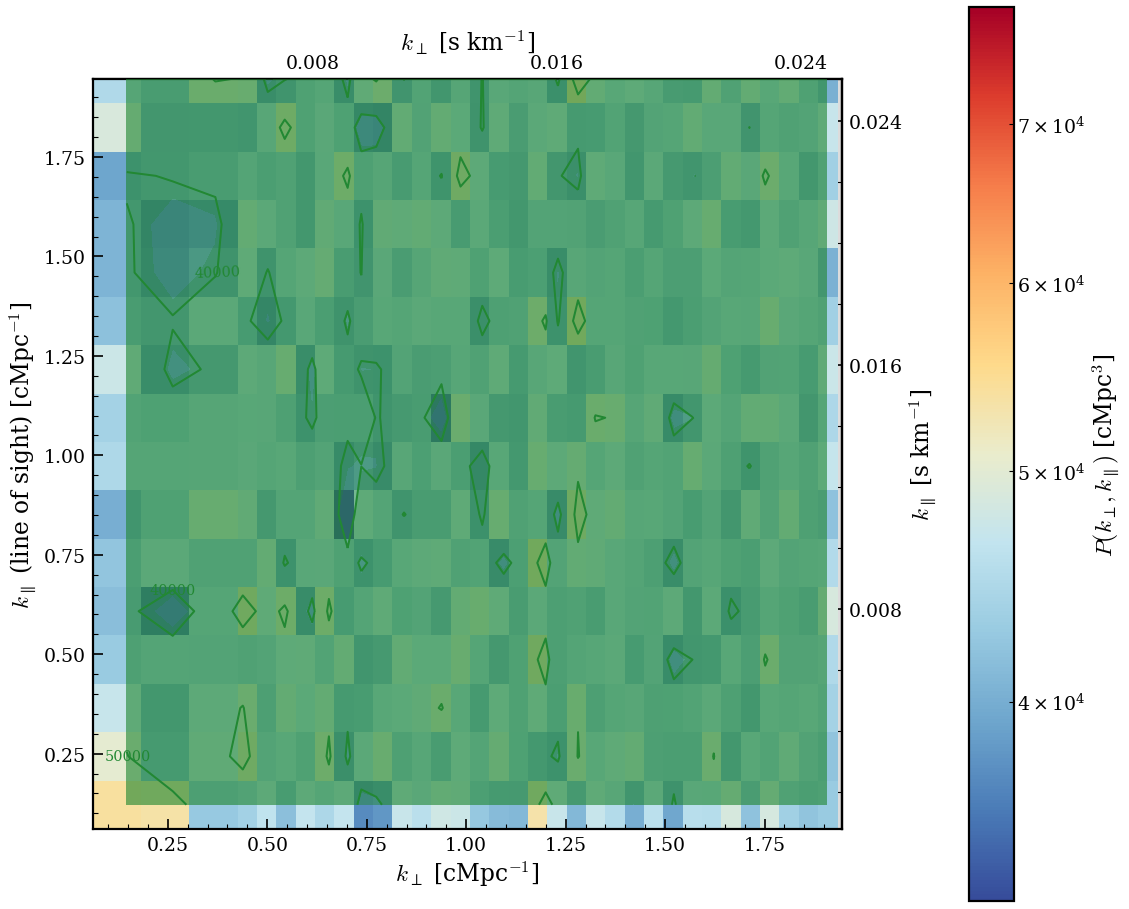

k map: 3961 rows, k_par = 2 pi m / L up to pi N_LOS / L = 481.7 cMpc^-1, shown up to the transverse Nyquist frequency pi / d_perp = 1.946 cMpc^-1 (a square map, as in D2); errors: 3 lines of sight (not independent)


In [8]:
from skewerjax.utils.plotting import plot_overflux_kpar_kperp, plot_overflux_rpar_rperp
densE = dict(dB["total"], axes=axB)
fig, ax, _ = plot_overflux_kpar_kperp(densE, kms_per_cMpc=u, kperp_edges=K_EDGES_B, n_sigma=1, unit="cMpc", kpar_max=k_nyq_b)  # drawn: k_par <= pi / d_perp, as the overflux map (D2)
plt.show()
print(f"k map: {axB['kpar_edges'].size - 1} rows, k_par = 2 pi m / L up to pi N_LOS / L = {np.pi * N_LOS / L:.1f} cMpc^-1, "
      f"shown up to the transverse Nyquist frequency pi / d_perp = {k_nyq_b:.3f} cMpc^-1 (a square map, as in D2); errors: {ENSEMBLE}")

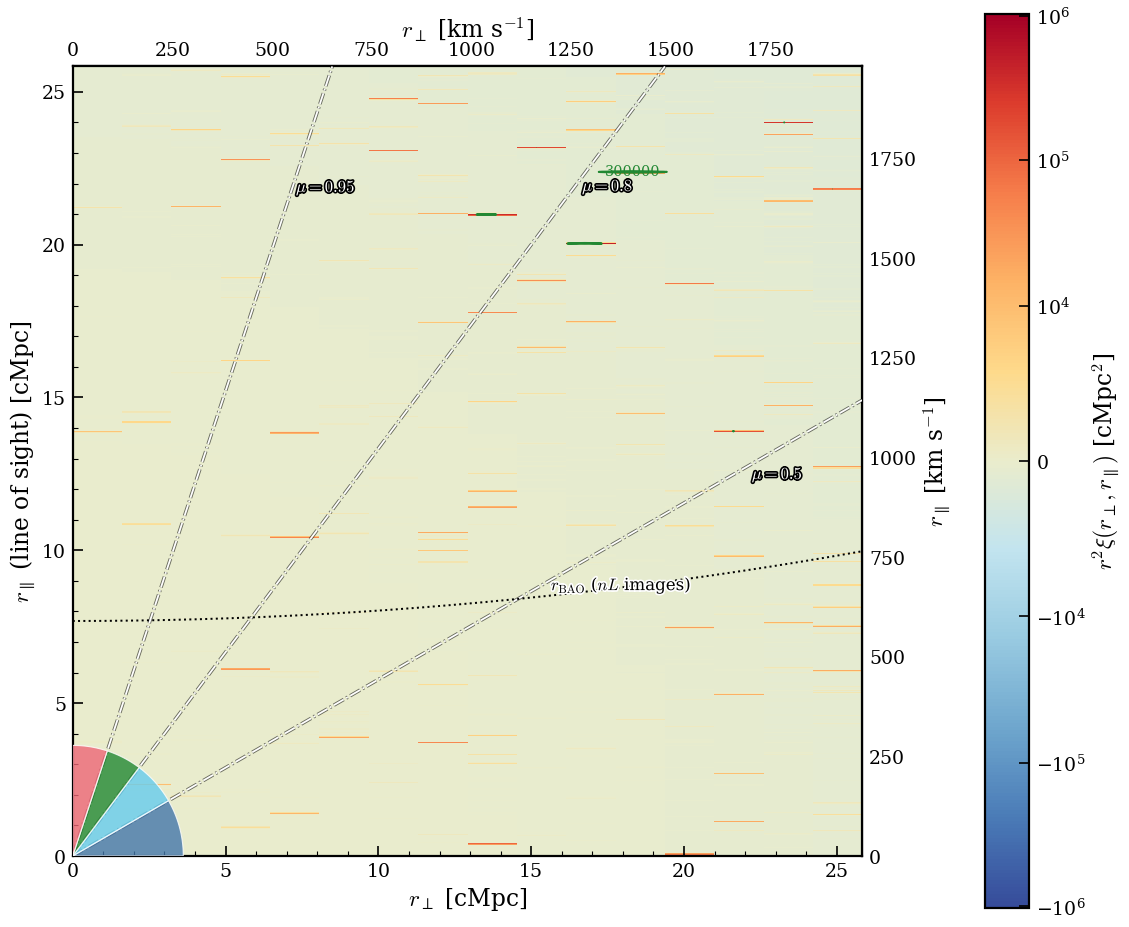

map: 3962 rows, one per separation j L / N_LOS from 0 to L / 2; r_BAO = r_d = 147.3 cMpc > L / 2 = 25.8 cMpc: the dotted arcs are its periodic images about (0, n L) (n_perp = 0; those across the line of sight are smeared by the average over r_perp)


In [9]:
fig, ax, _ = plot_overflux_rpar_rperp(densE, kms_per_cMpc=u, rperp_edges=RPERP_EDGES_B, r_bao=R_BAO, n_sigma=1, color_scale="symlog", quantity="r2xi", unit="cMpc")
plt.show()
print(f"map: {axB['rpar_edges'].size - 1} rows, one per separation j L / N_LOS from 0 to L / 2; r_BAO = r_d = {R_BAO:.1f} cMpc > L / 2 = {L / 2:.1f} cMpc: "
      f"the dotted arcs are its periodic images about (0, n L) (n_perp = 0; those across the line of sight are smeared by the average over r_perp)")

### B2 · The isotropic statistics of the density, against the whole box

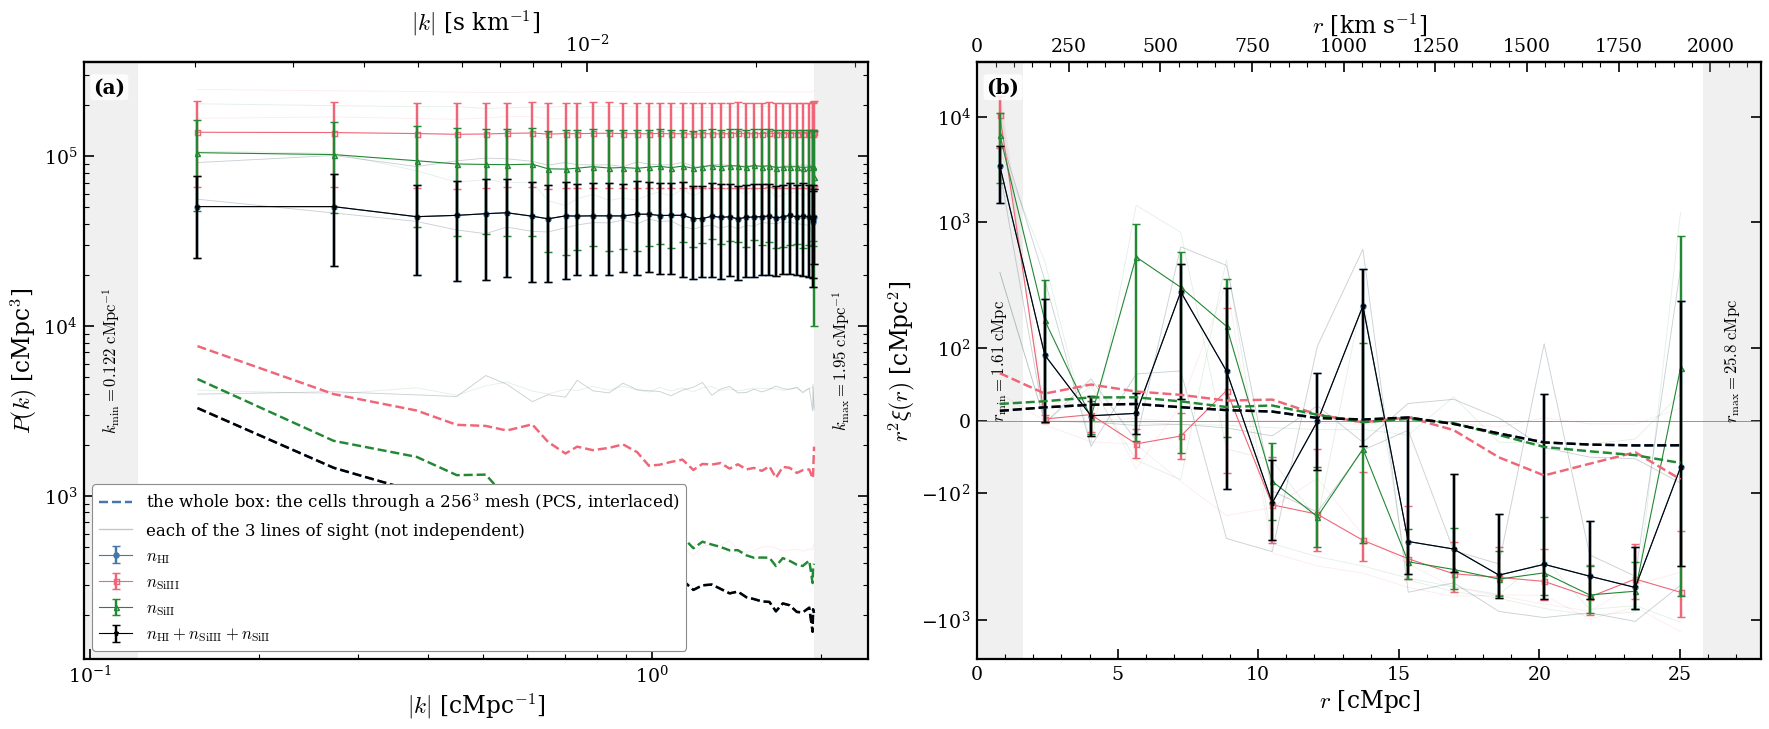

    HI: P on the skewers / P of the whole box in the first |k| bins [15.4 34.5 41.7]; transverse aliasing d_perp^2 P1D(2 pi / L) / P on the skewers at the lowest |k| = 0.88
 SiIII: P on the skewers / P of the whole box in the first |k| bins [18.2 34.7 42.8]; transverse aliasing d_perp^2 P1D(2 pi / L) / P on the skewers at the lowest |k| = 0.98
  SiII: P on the skewers / P of the whole box in the first |k| bins [21.5 48.5 55.5]; transverse aliasing d_perp^2 P1D(2 pi / L) / P on the skewers at the lowest |k| = 0.83
 total: P on the skewers / P of the whole box in the first |k| bins [15.4 34.5 41.7]; transverse aliasing d_perp^2 P1D(2 pi / L) / P on the skewers at the lowest |k| = 0.88


In [10]:
from skewerjax.utils.plotting import plot_overflux_3d
fig, axs = plot_overflux_3d(dB, axB, kms_per_cMpc=u, names=NAMES_B, k_edges=K_EDGES_B, r_edges=R_EDGES_B, limits=LIM_B, theory=REF_B,
                            theory_label=f"the whole box: the cells through a {N_MESH}$^3$ mesh ({MAS.upper()}, interlaced)", each_label=EACH,
                            quantity="r2xi", y_scale="symlog")
add_panel_letters([axs["P"], axs["xi"]])
plt.show()
lo = np.flatnonzero(np.isfinite(dB["total"]["P_iso"]))[:3]
p1d_b = DENS_STATS["density_p1d"]["p1d"]                       # P1D of the density along the skewers (fields, modes) [cMpc]
for jf, f in enumerate(dB):
    print(f"{f:>6}: P on the skewers / P of the whole box in the first |k| bins {np.round(dB[f]['P_iso'][lo] / REF_B[f]['P_iso'][lo], 1)}; "
          f"transverse aliasing d_perp^2 P1D(2 pi / L) / P on the skewers at the lowest |k| = {D_PERP**2 * p1d_b[jf, 1] / dB[f]['P_iso'][lo[0]]:.2f}")

## Part C — Transmission and overflux

$T = e^{-\tau}$, its mean $\bar T$ over the pixels of `MEAN` and $\delta = T/\bar T - 1$ (10, Part C). In one snapshot
every pixel has the same scale factor, so $\bar T(z)$ is one number, the global mean.

In [11]:
from skewerjax.summary_stats import ensemble_mean_transmissions, overflux_check
A_PIX = np.full(N_PIX, H.a)                                                     # the scale factor of every pixel: one snapshot
T = np.exp(-TAU)                                                                # the transmission of each line (3, N_lines, N_sk, N_PIX)
T_BAR = ensemble_mean_transmissions(T, mean=MEAN, grid=A_PIX)                   # T_bar of every line and of the total: (3, N_lines + 1, N_sk, N_PIX), a view
DELTA = np.concatenate([T, T.prod(axis=1, keepdims=True)], axis=1) / T_BAR - 1  # delta = T / T_bar - 1 (every line, total)
CHECK = overflux_check(DELTA, T_BAR, mean=MEAN, grid=A_PIX)                     # <delta> = 0 over the sets of MEAN, C, the decomposition
T_glob = ensemble_mean_transmissions(T, mean="global")
T_v = ensemble_mean_transmissions(T, mean="redshift")[0, :, 0]                  # without a grid: the mean at each pixel (a diagnostic)
print("mean transmission: " + ", ".join(f"{nm} {T_BAR[0, j, 0, 0]:.6f}" for j, nm in enumerate([*NAMES_L, "total"])) + "; per line of sight (Lya): "
      + ", ".join(f"{'xyz'[a - 1]} {T[i, 0].mean():.4f}" for i, a in enumerate(AXES)))
print(f"MEAN = {MEAN!r} on one snapshot (every pixel at a = {H.a:.5f}): the global mean, max |T_bar / T_bar_global - 1| = "
      f"{np.max(np.abs(T_BAR[:, :, 0] / T_glob[:, :, 0] - 1)):.1e}; the mean at each pixel instead would scatter by "
      f"{np.round((T_v / T_v.mean(axis=1, keepdims=True)).std(axis=1), 4)} (rms, every line and the total)")
print(f"normalisation: max |<delta>| over the sets of MEAN = {CHECK['mean_delta_level'].max():.1e}; C = T_bar / prod_j T_bar_j - 1 = "
      f"{CHECK['C']:.4e}, |C - sum_(|A| >= 2) <delta_A>| = {CHECK['C_error']:.1e}; max |[sum_A delta_A - C] / (1 + C) - delta_tot| = "
      f"{CHECK['decomposition_error']:.1e}")
del T

mean transmission: Lyα 0.533310, Si III 0.999526, Si II 1193 0.999818, Si II 1190 0.999854, total 0.532970; per line of sight (Lya): x 0.5347, y 0.5329, z 0.5323
MEAN = 'redshift' on one snapshot (every pixel at a = 0.24949): the global mean, max |T_bar / T_bar_global - 1| = 4.4e-16; the mean at each pixel instead would scatter by [0.0471 0.0003 0.0002 0.0002 0.0472] (rms, every line and the total)
normalisation: max |<delta>| over the sets of MEAN = 3.2e-16; C = T_bar / prod_j T_bar_j - 1 = 1.6354e-04, |C - sum_(|A| >= 2) <delta_A>| = 5.3e-16; max |[sum_A delta_A - C] / (1 + C) - delta_tot| = 1.1e-15


### C1 · One skewer, from the gas to the flux contrast

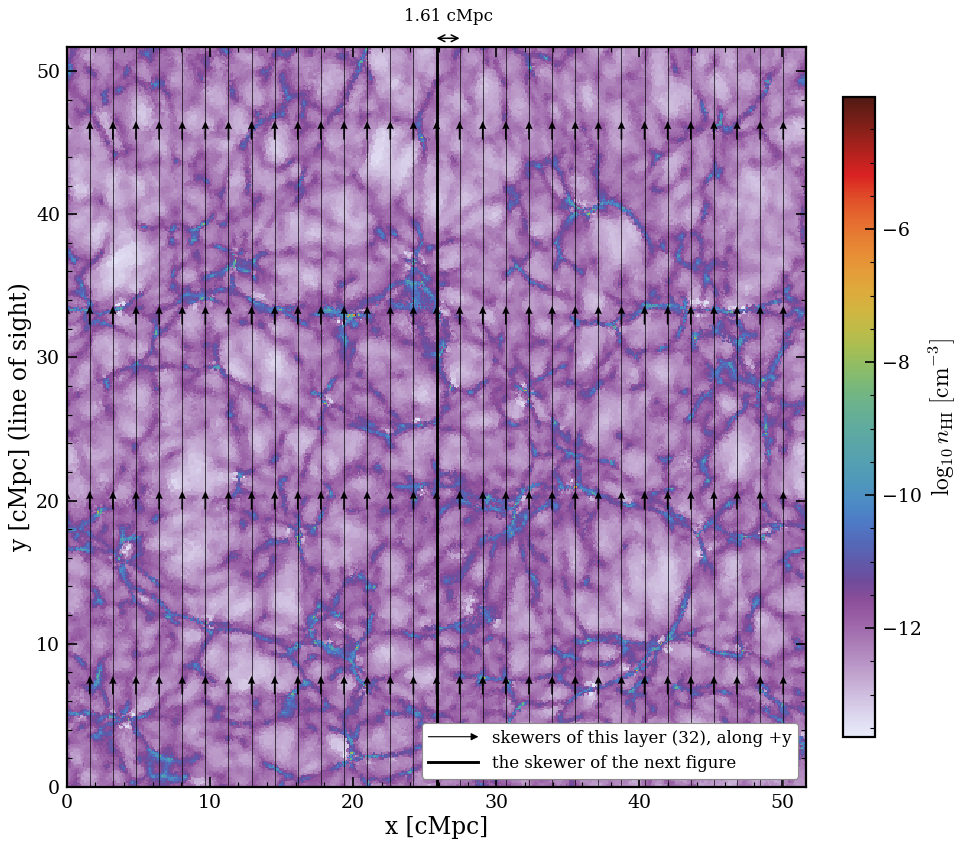

32 skewers in the plane z = 0.0 cMpc, 1.615 cMpc apart; the skewer of the next figure: x = 25.83 cMpc; the map: the n_HI of the Voronoi cell at every pixel centre (782,207 cells searched)


In [12]:
from skewerjax.simulations import voronoi_slice
from skewerjax.utils.plotting import plot_skewer_slice, plot_toy_skewer
k_y = AXES.index(2)                                                       # the skewers along y: x across, y along (as in 10)
on_z0 = np.flatnonzero(COLS[:, 1] == 0)
j = int(on_z0[np.argmin(np.abs(COLS[on_z0, 0] - N_SK // 2))])            # the skewer nearest to x = L/2 in the layer z = 0
ix, iz = COLS[j]
SLICE = voronoi_slice(CELLS, "HI", 3, iz * D_PERP, n_pix=512)             # the Voronoi cells cut by the plane z = 0: n_HI
fig, ax, sl_info = plot_skewer_slice(SLICE["n"], L, COLS, z_index=0, highlight=(ix, iz), spacing=D_PERP)
plt.show()
print(f"{sl_info['n_row']} skewers in the plane z = {iz * D_PERP:.1f} cMpc, {sl_info['spacing_cMpc']:.4g} cMpc apart; the skewer of the "
      f"next figure: x = {ix * D_PERP:.2f} cMpc; the map: the n_HI of the Voronoi cell at every pixel centre ({SLICE['n_cells']:,} cells searched)")

The metal lines absorb little in this snapshot (their $\bar T$ in Part C): the total lies on the $\mathrm{Ly}\alpha$ curve.

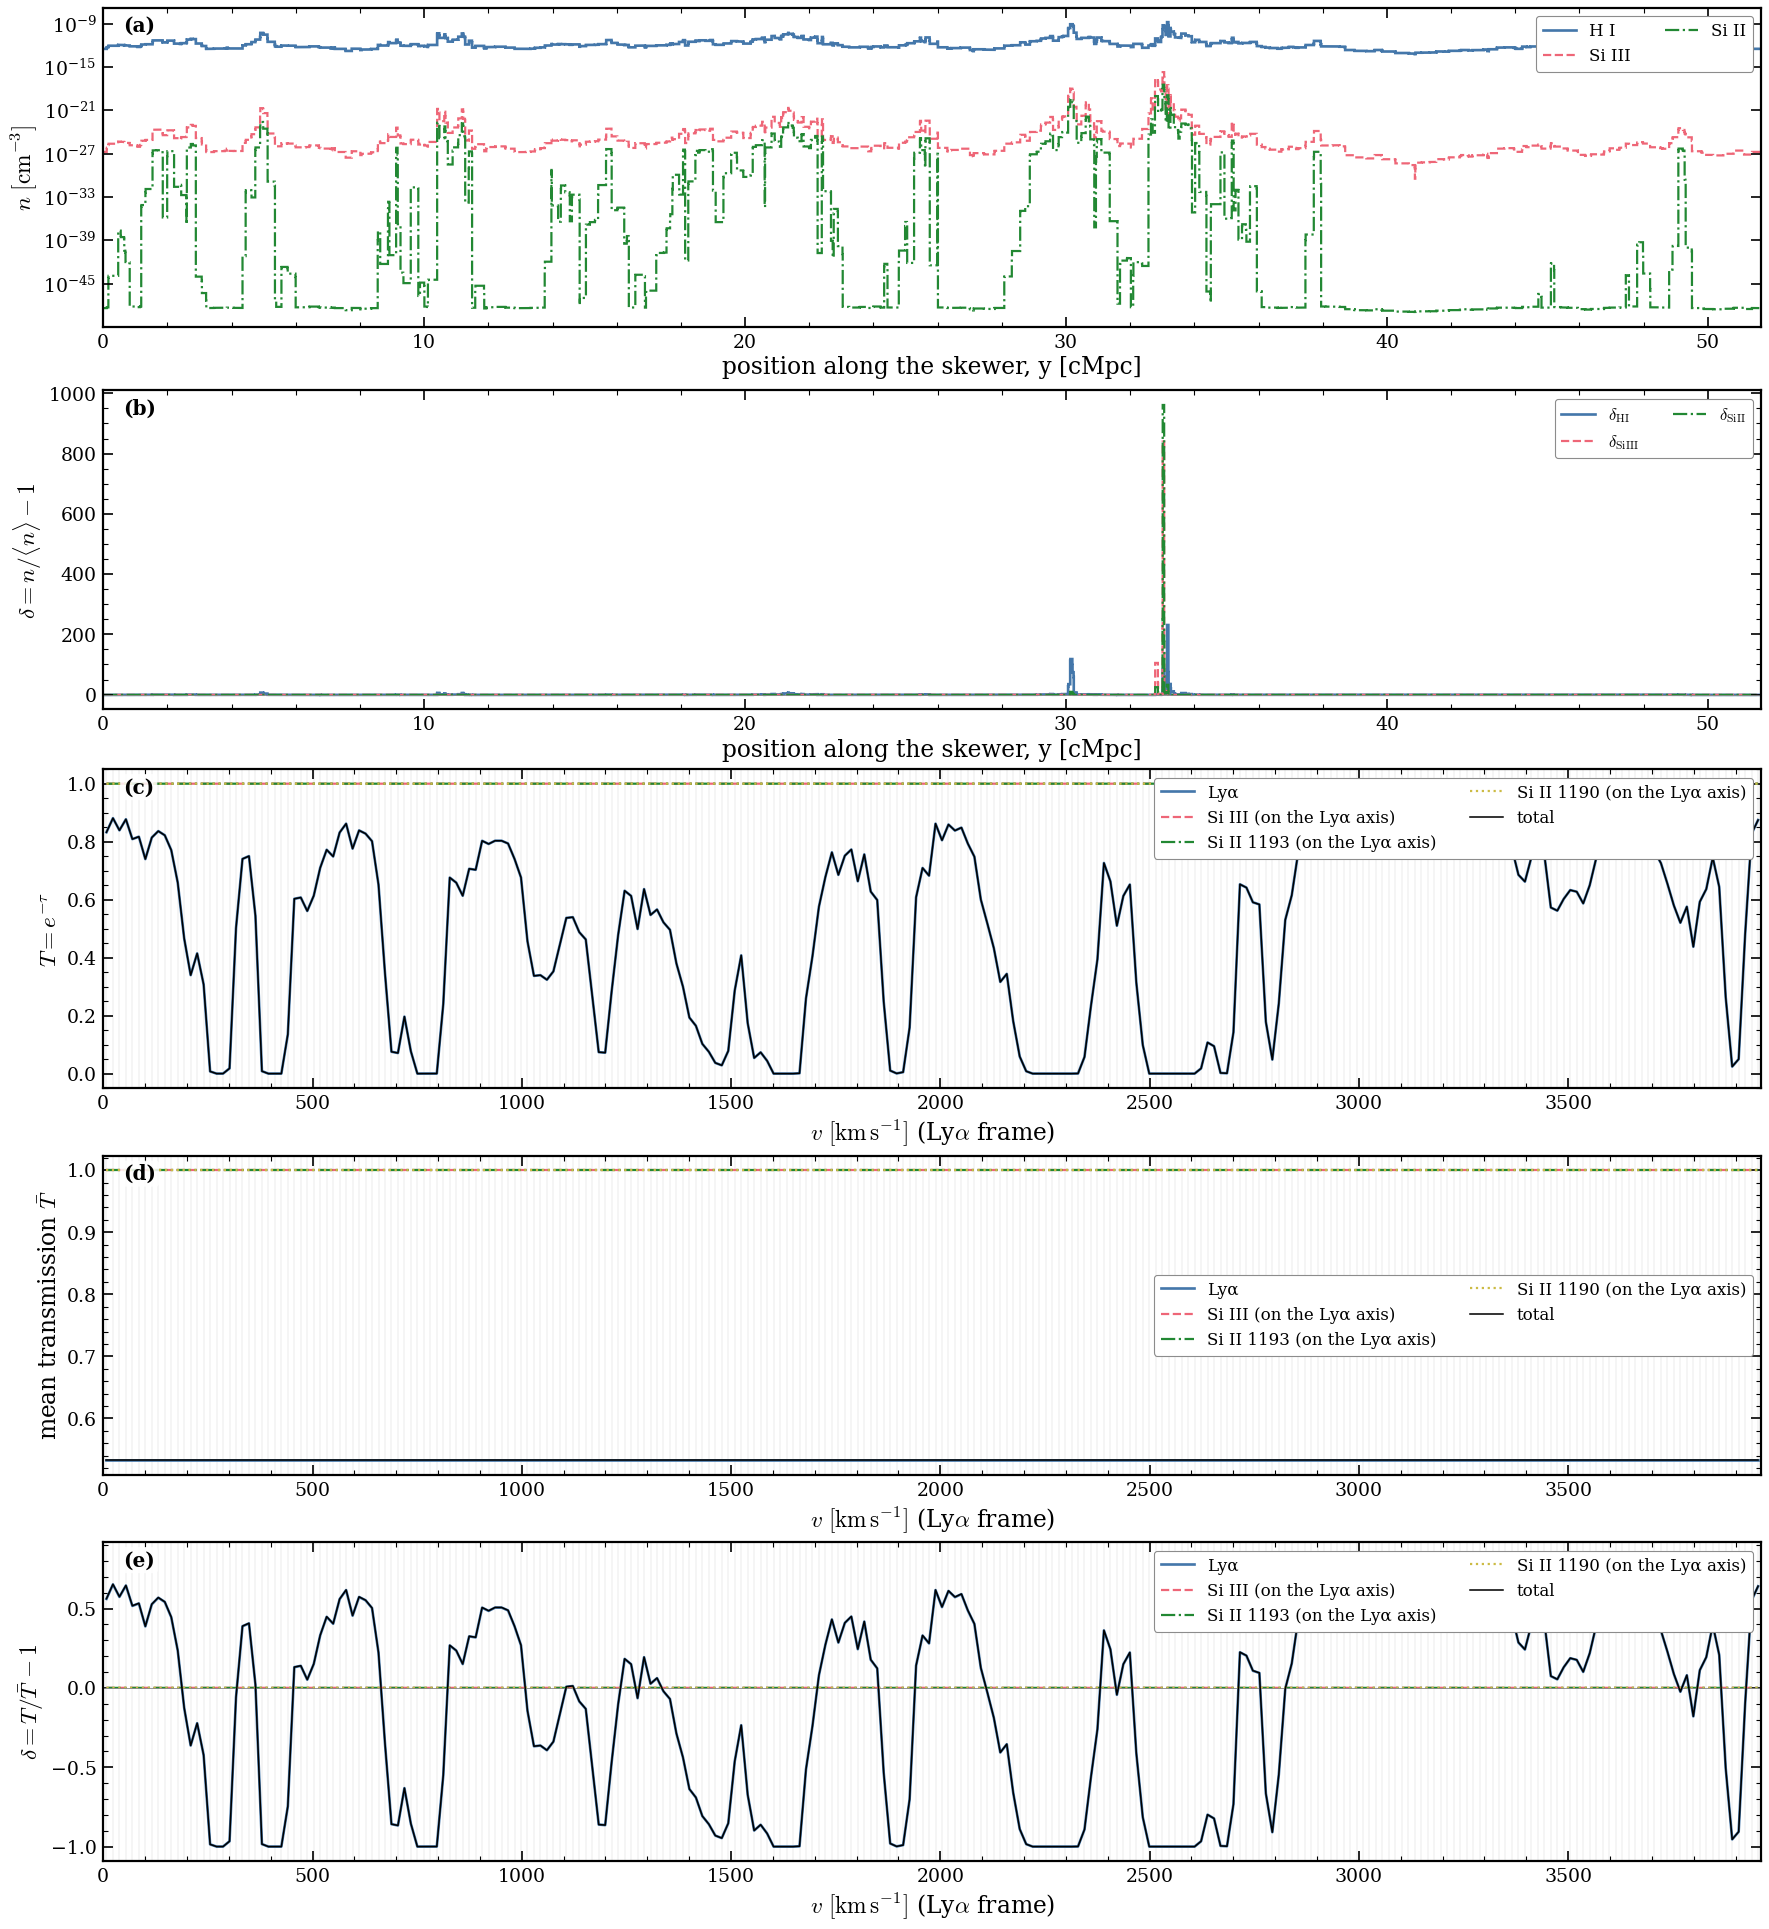

line separations Delta v [km/s], folded into [0, v_per / 2] with v_per = 3961.5 km/s [km/s and cMpc]: Lyα–Si III 2270.0 -> 1691.6 = 22.06; Lyα–Si II 1193 5570.6 -> 1609.0 = 20.99; Lyα–Si II 1190 6293.5 -> 1629.6 = 21.25; Si III–Si II 1193 3300.6 -> 660.9 = 8.62; Si III–Si II 1190 4023.5 -> 62.0 = 0.81; Si II 1193–Si II 1190 722.9 -> 722.9 = 9.43
b(Lya) / b(Si) = 5.28


In [13]:
from skewerjax.utils.plotting import line_pairs
n_sk1 = {sp: DENS[k_y][sp][ix, :, iz] for sp in LINES.species_keys}       # the density at the points of this skewer
fig, axs, grid_info = plot_toy_skewer(L, n_sk1, V, TAU[k_y][:, j], mean_transmission=T_BAR[k_y][:, j], line_ids=LINE_IDS)
add_panel_letters(axs)
plt.show()
PAIRS = line_pairs(LINE_IDS, np.asarray(LINES.delta_v), PERIOD)           # every pair of lines, its separation folded into [0, v_per / 2]
dv_12 = float(LINES.delta_v[1])
dv_fold = PAIRS[0]["fold"]                                                # Si III - Lya, folded
print(f"line separations Delta v [km/s], folded into [0, v_per / 2] with v_per = {PERIOD:.1f} km/s [km/s and cMpc]: " + "; ".join(
      f"{NAMES_L[p['i']]}–{NAMES_L[p['j']]} {p['dv']:.1f} -> {p['fold']:.1f} = {p['fold'] / u:.2f}" for p in PAIRS))
print(f"b(Lya) / b(Si) = {b_1e4[LINE_IDS[0]] / b_1e4[LINE_IDS[1]]:.2f}")

## Part D — Summary statistics of the overfluxes

As 10's Part D: along the line of sight a velocity $v$ [km/s], across it comoving distances [cMpc], related by
$u = aH$ (exact here: one snapshot); the statistics on exactly the lattice of the skewers. Errors: the mean over the
3 lines of sight and its error; the three share the gas, so the error understates the cosmic variance.

### D1 · The bins and the statistics

In [14]:
# The bins of the 3D statistics of the overfluxes (D1) in comoving units [cMpc], [cMpc^-1] (the line of sight converted with u)
dv_c = DV / u                                                                   # a pixel dv / u [cMpc]
dr_c = max(D_PERP, dv_c)
RPERP_EDGES_C = np.arange(0, L / 2 + D_PERP, D_PERP)                           # r_perp: width L / N_SK to L / 2 (first bin: the same skewer)
R_EDGES_C = np.arange(0, L / 2 + dr_c, dr_c)                                    # |r| (and the wedges): the coarser spacing, to L / 2
k_nyq_c = min(np.pi / D_PERP, np.pi / dv_c)
K_EDGES_C = bao_k_edges(2 * np.pi / L, k_nyq_c, k_nyq_c, k_1=None, dk_factor=0.4)   # |k|: as Part B, to the smaller Nyquist frequency
EDGES_C = dict(k_edges=K_EDGES_C, r_edges=R_EDGES_C, rperp_edges=RPERP_EDGES_C)
print(f"overflux bins: r_perp {RPERP_EDGES_C.size - 1} of width {D_PERP:.4g} cMpc; r_par one row per pixel separation, {N_PIX // 2 + 1} "
      f"rows from 0 to v_per / 2; |r| {R_EDGES_C.size - 1} of width {dr_c:.4g} cMpc; |k| {K_EDGES_C.size - 1} up to {K_EDGES_C[-1]:.4f} cMpc^-1")

overflux bins: r_perp 16 of width 1.615 cMpc; r_par one row per pixel separation, 129 rows from 0 to v_per / 2; |r| 16 of width 1.615 cMpc; |k| 46 up to 1.9457 cMpc^-1


In [15]:
from skewerjax.summary_stats import GRID_KEYS, ensemble_mean, measure_lattice, skewer_p1d, skewer_xi1d
OVERFLUX_FIELDS = (*LINE_IDS, "total")                          # the overflux of each line and of the total
GRID_C = lattice_grid(N_SK, N_SK, N_PIX, L, D_PERP, **EDGES_C, log=print)   # the 3D statistics on the lattice, bins EDGES_C
P1D_EACH, XI1D_EACH, F3D_EACH = [], [], []
for i in range(n_ax):                                           # every statistic per line of sight, from arrays and geometry only
    K1D, p = skewer_p1d(DELTA[i], DV)                           # P1D (N_lines + 1, N_PIX / 2 + 1): one 1D FFT per skewer [km/s]
    LAGS, x = skewer_xi1d(DELTA[i], DV)                         # xi1D (N_lines + 1, N_PIX / 2 + 1) at every lag j dv
    P1D_EACH.append(dict(p1d=p))
    XI1D_EACH.append(dict(xi1d=x))
    # on its own lattice: exact FFT, no assignment (lattice-native; mas=None)
    F3D_EACH.append({f: measure_lattice(DELTA[i, jf], GRID_C) for jf, f in enumerate(OVERFLUX_FIELDS)})
P1D = dict(ensemble_mean(P1D_EACH, ("p1d",)), k=K1D)            # the mean over the 3 lines of sight and its error, k [s/km]
XI1D = dict(ensemble_mean(XI1D_EACH, ("xi1d",)), lags=LAGS)
FLUX3D = {f: ensemble_mean([r[f] for r in F3D_EACH], GRID_KEYS) for f in OVERFLUX_FIELDS}
AXES3D = GRID_C.axes()
print(f"statistics of {ENSEMBLE}: P1D and xi1D of {len(OVERFLUX_FIELDS)} overfluxes along {n_sk} skewers each, the 3D statistics on "
      f"the lattice {GRID_C.shape} (overflux) and {GRID_B.shape} (density)")

statistics of 3 lines of sight (not independent): P1D and xi1D of 5 overfluxes along 1024 skewers each, the 3D statistics on the lattice (32, 256, 32) (overflux) and (32, 7923, 32) (density)


### D2 · The $(k_\perp, k_\parallel)$ & $(r_\perp, r_\parallel)$ planes

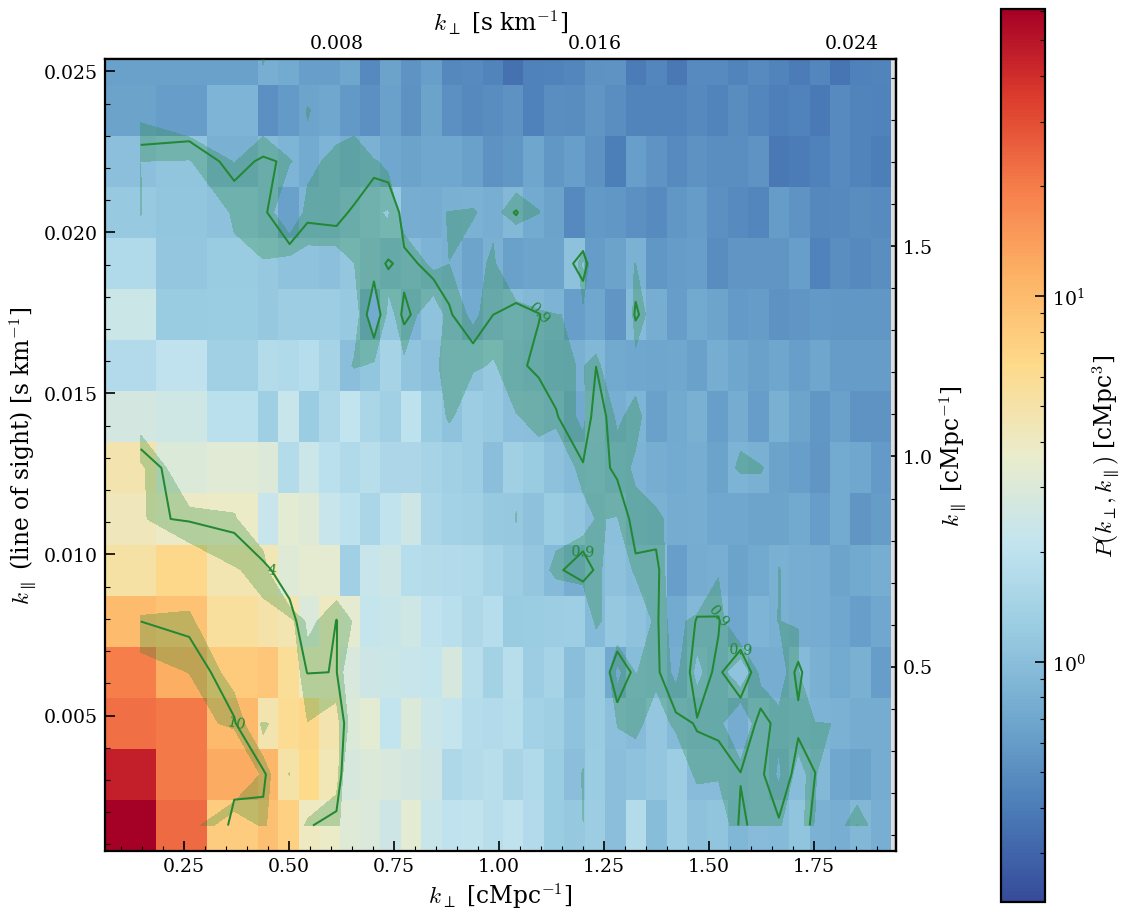

k map: 128 rows, k_par = 2 pi m / v_per from 1.59e-03 to pi / dv = 2.03e-01 s/km; 46 columns of k_perp (K_EDGES_C), of which 11 hold no mode; shown up to k_par = pi / d_perp = 0.0254 s/km


In [16]:
from skewerjax.utils.plotting import fold_periodic, line_pair_label, plot_xi_mu_wedges
ax3, f3 = AXES3D, FLUX3D
from skewerjax.utils.plotting import field_names
NAMES = field_names(OVERFLUX_FIELDS)                                    # Lyα, Si III, Si II 1193, Si II 1190, total
tot = dict(f3["total"], axes=ax3)
fig, ax, _ = plot_overflux_kpar_kperp(tot, kms_per_cMpc=u, kperp_edges=K_EDGES_C, n_sigma=1, kpar_max=k_nyq_c)  # drawn: k_par <= pi / d_perp (square)
plt.show()
print(f"k map: {ax3['kpar_edges'].size - 1} rows, k_par = 2 pi m / v_per from {2 * np.pi / PERIOD:.2e} to pi / dv = {np.pi / DV:.2e} s/km; "
      f"{ax3['kperp_edges'].size - 1} columns of k_perp (K_EDGES_C), of which {int(np.sum(ax3['n_modes_P_map'].sum(0) == 0))} hold no mode; "
      f"shown up to k_par = pi / d_perp = {k_nyq_c / u:.4f} s/km")

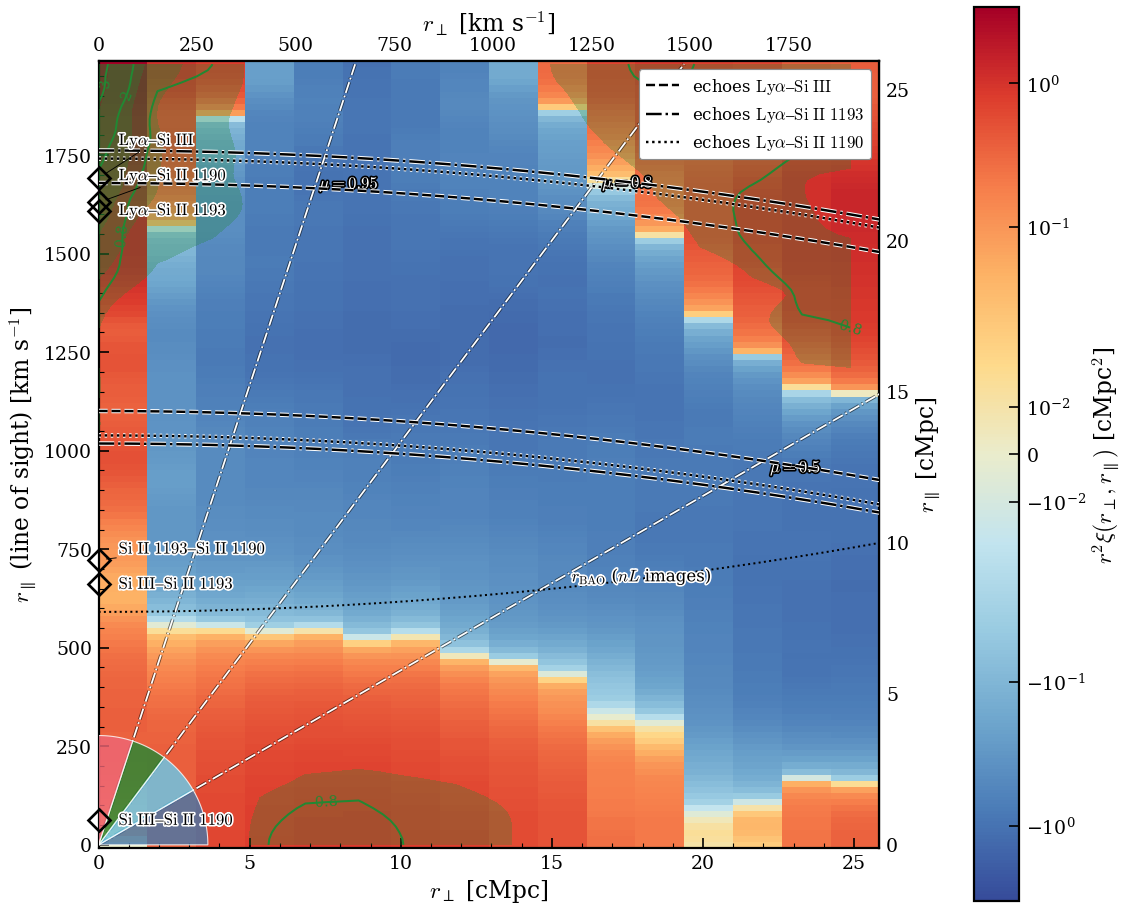

map: 129 rows, one per pixel separation j dv (dv = 15.47 km/s) from 0 to 1981 km/s = v_per / 2; the spots of the 6 pairs (folded) at r_par = 1692, 1609, 1630, 661, 62, 723 km/s; r_BAO > L / 2: its images and their echoes (n_perp = 0) as arcs
Si III - Lya at r_par = Delta, r_perp bin 0 (0.00-1.61 cMpc): xi = 3.79e-03, excess over the rows two pixels away 6.49e-05 = 0.0 sigma (3 lines of sight (not independent))
Si III - Lya at r_par = Delta, r_perp bin 1 (1.61-3.23 cMpc): xi = 6.87e-04, excess over the rows two pixels away -3.25e-05 = -0.0 sigma (3 lines of sight (not independent))


In [17]:
fig, ax, curves = plot_overflux_rpar_rperp(tot, kms_per_cMpc=u, rperp_edges=RPERP_EDGES_C, r_bao=R_BAO, delta_v=np.asarray(LINES.delta_v), line_ids=LINE_IDS,
                                           pairs="reference", n_sigma=1, color_scale="symlog", quantity="r2xi")  # a diamond per pair; the echoes of the pairs with Lyα
plt.show()
SEP = dv_fold / u                                                        # the line separation in comoving units [cMpc], folded
print(f"map: {ax3['rpar_edges'].size - 1} rows, one per pixel separation j dv (dv = {DV:.2f} km/s) from 0 to {u * ax3['rpar'][-1]:.0f} km/s = v_per / 2; "
      f"the spots of the {len(PAIRS)} pairs (folded) at r_par = " + ", ".join(f"{p['fold']:.0f}" for p in PAIRS) + " km/s; r_BAO > L / 2: its images and "
      f"their echoes (n_perp = 0) as arcs")
X, Xe = f3["total"]["xi_map"], f3["total"]["xi_map_err"]
ip = int(np.argmin(np.abs(ax3["rpar"] - SEP)))                           # the r_par row of the spot
for q in (0, 1):                                    # r_perp columns: 0 = pairs on the same skewer, 1 = one transverse spacing
    excess = X[ip, q] - 0.5 * (X[ip - 2, q] + X[ip + 2, q])
    print(f"Si III - Lya at r_par = Delta, r_perp bin {q} ({ax3['rperp_edges'][q]:.2f}-{ax3['rperp_edges'][q + 1]:.2f} cMpc): xi = {X[ip, q]:.2e}, "
          f"excess over the rows two pixels away {excess:.2e} = {excess / Xe[ip, q]:.1f} sigma ({ENSEMBLE})")

### D3 · Power spectrum, correlation function and wedges of the overfluxes

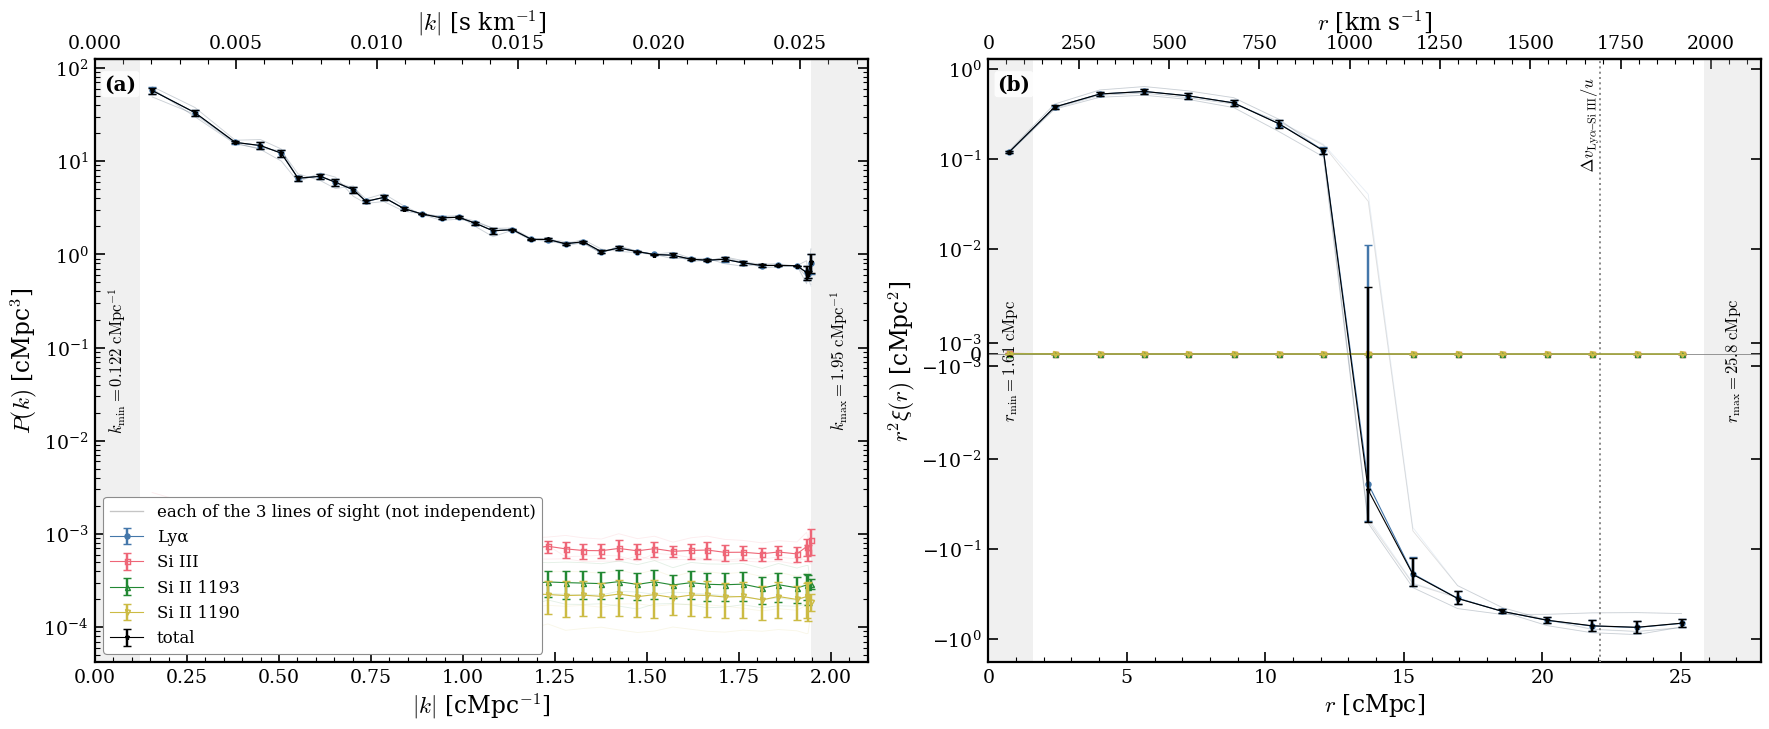

lattice 32 x 256 x 32 per line of sight, a cube of side L = 51.67 cMpc (v_per = 3962 km/s along the line of sight)
|k| from 0.061 to k_N = 1.946 cMpc^-1 in 46 bins: Nyquist pi N_pix / L = 15.566 cMpc^-1 along the line of sight, pi / d_perp = 1.946 cMpc^-1 across it
P_line / P_tot at the lowest |k|: HI-LyA 1.002, SiIII-1206 0.000, SiII-1193 0.000, SiII-1190 0.000


In [18]:
fig, axs = plot_overflux_3d(f3, ax3, kms_per_cMpc=u, r_bao=None, r_marks={line_pair_label(p['ids'], comoving=True, all_ids=LINE_IDS): p['fold'] / u for p in PAIRS[:1]},
                            names=NAMES, k_edges=K_EDGES_C, r_edges=R_EDGES_C, limits=lim, quantity="r2xi", y_scale="symlog", k_scale="linear",
                            each_label=EACH)
add_panel_letters([axs["P"], axs["xi"]])
plt.show()
PT = f3["total"]["P_iso"]
print(f"lattice {N_SK} x {N_PIX} x {N_SK} per line of sight, a cube of side L = {L:.2f} cMpc (v_per = {PERIOD:.0f} km/s along the line of sight)")
print(f"|k| from {ax3['k_edges'][0]:.3f} to k_N = {ax3['k_edges'][-1]:.3f} cMpc^-1 in {ax3['k_edges'].size - 1} bins: Nyquist pi N_pix / L = "
      f"{lim['k_nyq_par']:.3f} cMpc^-1 along the line of sight, pi / d_perp = {lim['k_nyq_perp'][0]:.3f} cMpc^-1 across it")
print("P_line / P_tot at the lowest |k|: " + ", ".join(f"{f} {f3[f]['P_iso'][0] / PT[0]:.3f}" for f in LINE_IDS))

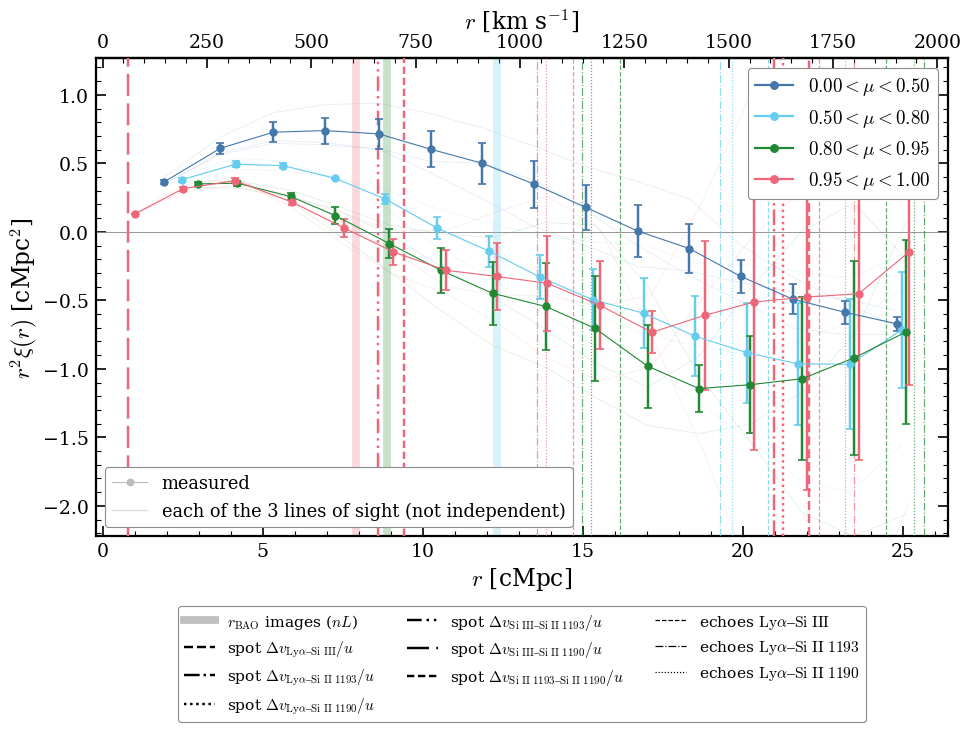

the Si III - Lya spot at r = 22.06 cMpc (mu = 1 wedge only); r^2 xi of the total in the |r| bin of the spot [cMpc^2]: 0.00 < mu < 0.50: -0.492 +- 0.110; 0.50 < mu < 0.80: -0.963 +- 0.444; 0.80 < mu < 0.95: -1.072 +- 0.595; 0.95 < mu < 1.00: -0.476 +- 1.405


In [19]:
fig, axs, _ = plot_xi_mu_wedges(tot, r_edges=R_EDGES_C, r_bao=R_BAO, delta_v=np.asarray(LINES.delta_v), line_ids=LINE_IDS, box=L, kms_per_cMpc=u, quantity="r2xi", y_scale="linear",
                                each_label=EACH)
plt.show()
mu_e, r_mu = ax3["mu_edges"], ax3["r_mu"]
js = np.nanargmin(np.abs(r_mu - SEP), axis=1)
print(f"the Si III - Lya spot at r = {SEP:.2f} cMpc (mu = 1 wedge only); r^2 xi of the total in the |r| bin of the spot [cMpc^2]: " + "; ".join(
      f"{mu_e[w]:.2f} < mu < {mu_e[w + 1]:.2f}: {r_mu[w, jj]**2 * f3['total']['xi_mu'][w, jj]:+.3f} +- {r_mu[w, jj]**2 * f3['total']['xi_mu_err'][w, jj]:.3f}"
      for w, jj in enumerate(js)))

### D4 · P1D next to a DESI measurement

The DESI DR1 P1D at $z = 3.0$ (Chaves-Montero et al., Fig. 1; the snapshot is at $z = 3.008$), read from the vector
paths of the figure with its error bars (`utils.reference_data`). The simulation's mean transmission is not rescaled to
the observed one.

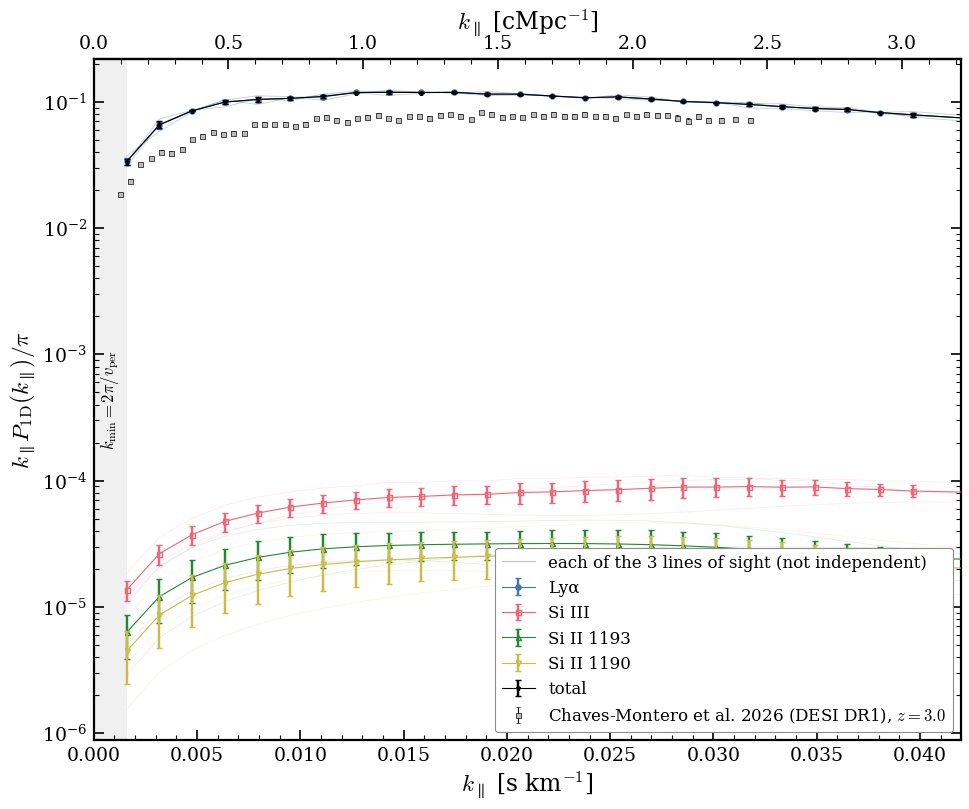

snapshot z = 3.008, reference z = 3; reference / simulation (Lya) over the reference's k range: median 0.67, from 0.54 to 0.77
line separations: periods 2 pi / Delta v [s/km]: Lyα–Si III 0.0028, Lyα–Si II 1193 0.0011, Lyα–Si II 1190 0.0010, Si III–Si II 1193 0.0019, Si III–Si II 1190 0.0016, Si II 1193–Si II 1190 0.0087; k_min = 2 pi / v_per = 1.59e-03, k_max = pi / dv = 0.203 s/km


In [20]:
from skewerjax.utils.plotting import plot_p1d_reference
from skewerjax.utils.reference_data import P1D_DESI_DR1_Z30 as P1D_REF
K_EDGES_1D = bao_k_edges(2 * np.pi / PERIOD, np.pi / DV, 0.04, k_1=None, dk_factor=0.25, n_log=12)  # [s/km]: steps of k_f / 4 to 0.04, then log
K_LIMITS_1D = (2 * np.pi / PERIOD, np.pi / DV)                                   # k_min, k_max of the line of sight [s/km]
fig, ax = plot_p1d_reference(P1D, P1D_REF, names=NAMES, k_max=P1D_REF["k_max_figure"], k_edges=K_EDGES_1D, k_limits=K_LIMITS_1D,
                             kms_per_cMpc=u, each_label=EACH)
plt.show()
kc = P1D["k"]
sim = np.interp(P1D_REF["k"], kc, kc * P1D["p1d"][0] / np.pi)
print(f"snapshot z = {H.redshift:.3f}, reference z = {P1D_REF['z']:g}; reference / simulation (Lya) over the reference's k range: median "
      f"{np.median(P1D_REF['kP_pi'] / sim):.2f}, from {np.min(P1D_REF['kP_pi'] / sim):.2f} to {np.max(P1D_REF['kP_pi'] / sim):.2f}")
print("line separations: periods 2 pi / Delta v [s/km]: " + ", ".join(f"{NAMES_L[p['i']]}–{NAMES_L[p['j']]} {2 * np.pi / p['dv']:.4f}" for p in PAIRS) + "; k_min = 2 pi / v_per = "
      f"{2 * np.pi / PERIOD:.2e}, k_max = pi / dv = {np.pi / DV:.3f} s/km")

### D5 · The decomposition by order

`decompose_1d` (opt-in, as in 10, D5): P1D and $\xi_{\rm 1D}$ of the total split into the pairs of subset terms and their
orders.

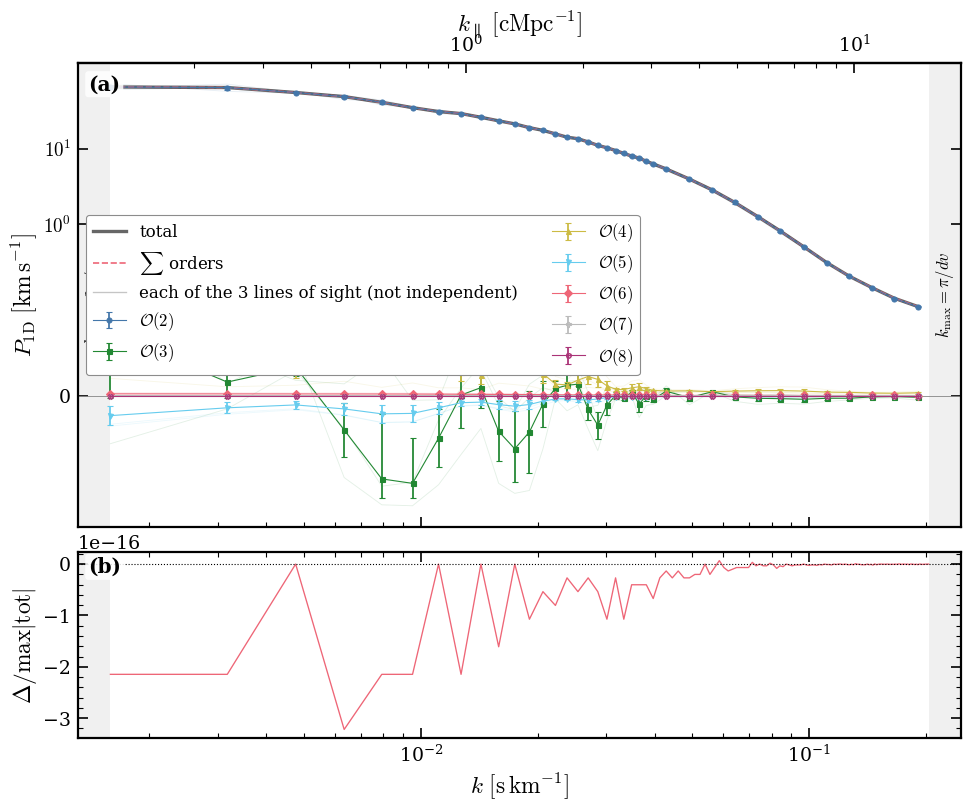

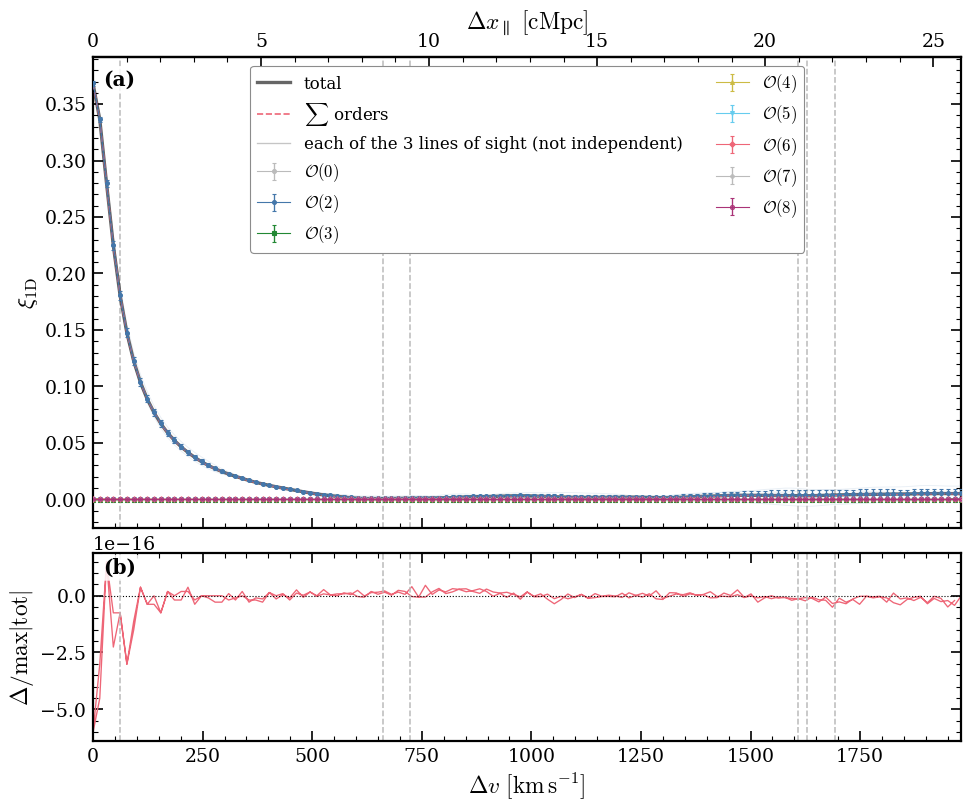

max |sum of the orders - total| / max |total|: P 2.7e-16, xi 6.0e-16; order 1 / max |total|: P 9.7e-18
the total of the decomposition against the per-skewer statistics of D1: P1D 1.1e-15, xi1D 1.6e-16 (relative)
orders: 0, 1, 2, 3, 4, 5, 6, 7, 8 (4 lines: 0 .. 2 N_lines); cos(k Delta v) of Si III - Lya: period 2.77e-03 s/km = 1.75 mode spacings (2 pi / v_per)


In [21]:
from skewerjax.summary_stats import decompose_1d, ensemble_1d
from skewerjax.utils.plotting import plot_p1d_orders, plot_xi1d_orders
FLUX_ORDERS = ensemble_1d([decompose_1d(TAU[i], DV, T_BAR[i], mean=MEAN) for i in range(n_ax)])  # opt-in
dv_lines = np.asarray(LINES.delta_v)                                             # the offsets of every line: every pair's separation
fig, axs = plot_p1d_orders(FLUX_ORDERS, k_edges=K_EDGES_1D, k_limits=K_LIMITS_1D, kms_per_cMpc=u, each_label=EACH)
add_panel_letters(axs)
plt.show()
fig, axs = plot_xi1d_orders(FLUX_ORDERS, delta_v_list=dv_lines, kms_per_cMpc=u, each_label=EACH)  # every lag, 0 .. v_per / 2
add_panel_letters(axs)
plt.show()
e = FLUX_ORDERS
print(f"max |sum of the orders - total| / max |total|: P {np.abs(e['P_order'].sum(0) - e['P_total']).max() / np.abs(e['P_total']).max():.1e}, "
      f"xi {np.abs(e['xi_order'].sum(0) - e['xi_total']).max() / np.abs(e['xi_total']).max():.1e}; order 1 / max |total|: "
      f"P {np.abs(e['P_order'][1]).max() / np.abs(e['P_total']).max():.1e}")
xi_c, xi_d = e["xi_total"][N_PIX // 2:], XI1D["xi1d"][-1][: N_PIX // 2]  # the lags 0 .. v_per / 2 - dv (centred lags: 0 at N_PIX / 2)
print(f"the total of the decomposition against the per-skewer statistics of D1: P1D {np.abs(e['P_total'] - P1D['p1d'][-1]).max() / P1D['p1d'][-1].max():.1e}, "
      f"xi1D {np.abs(xi_c - xi_d).max() / np.abs(xi_d).max():.1e} (relative)")
print("orders: " + ", ".join(str(n) for n in range(e["P_order"].shape[0])) + f" ({len(LINE_IDS)} lines: 0 .. 2 N_lines); cos(k Delta v) of Si III - Lya: period "
      f"{2 * np.pi / abs(dv_12):.2e} s/km = {PERIOD / abs(dv_12):.2f} mode spacings (2 pi / v_per)")

### D6 · Each order, term by term

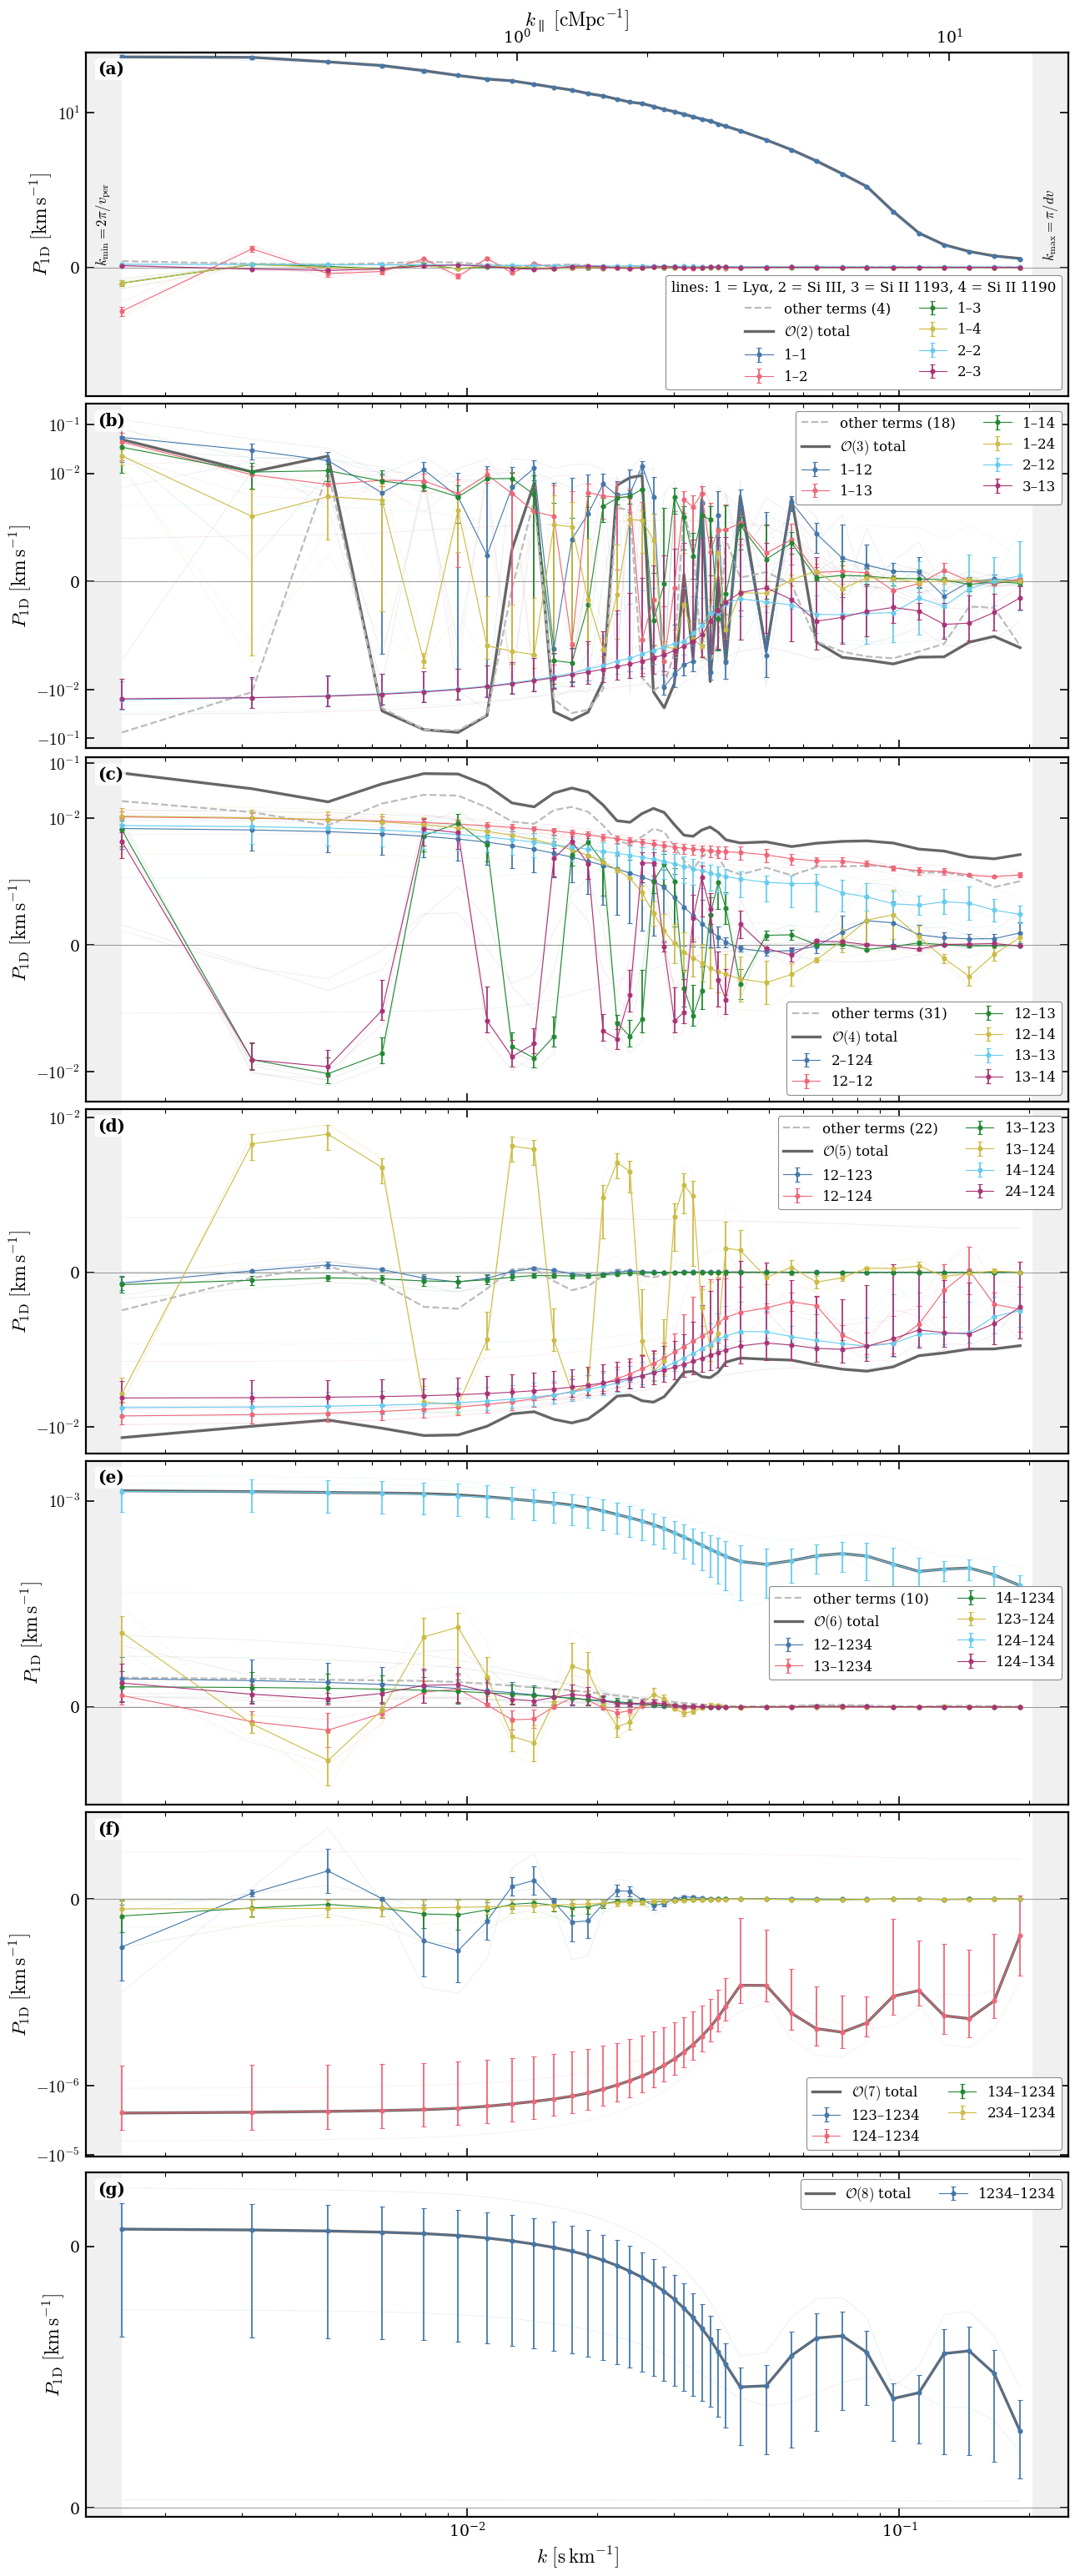

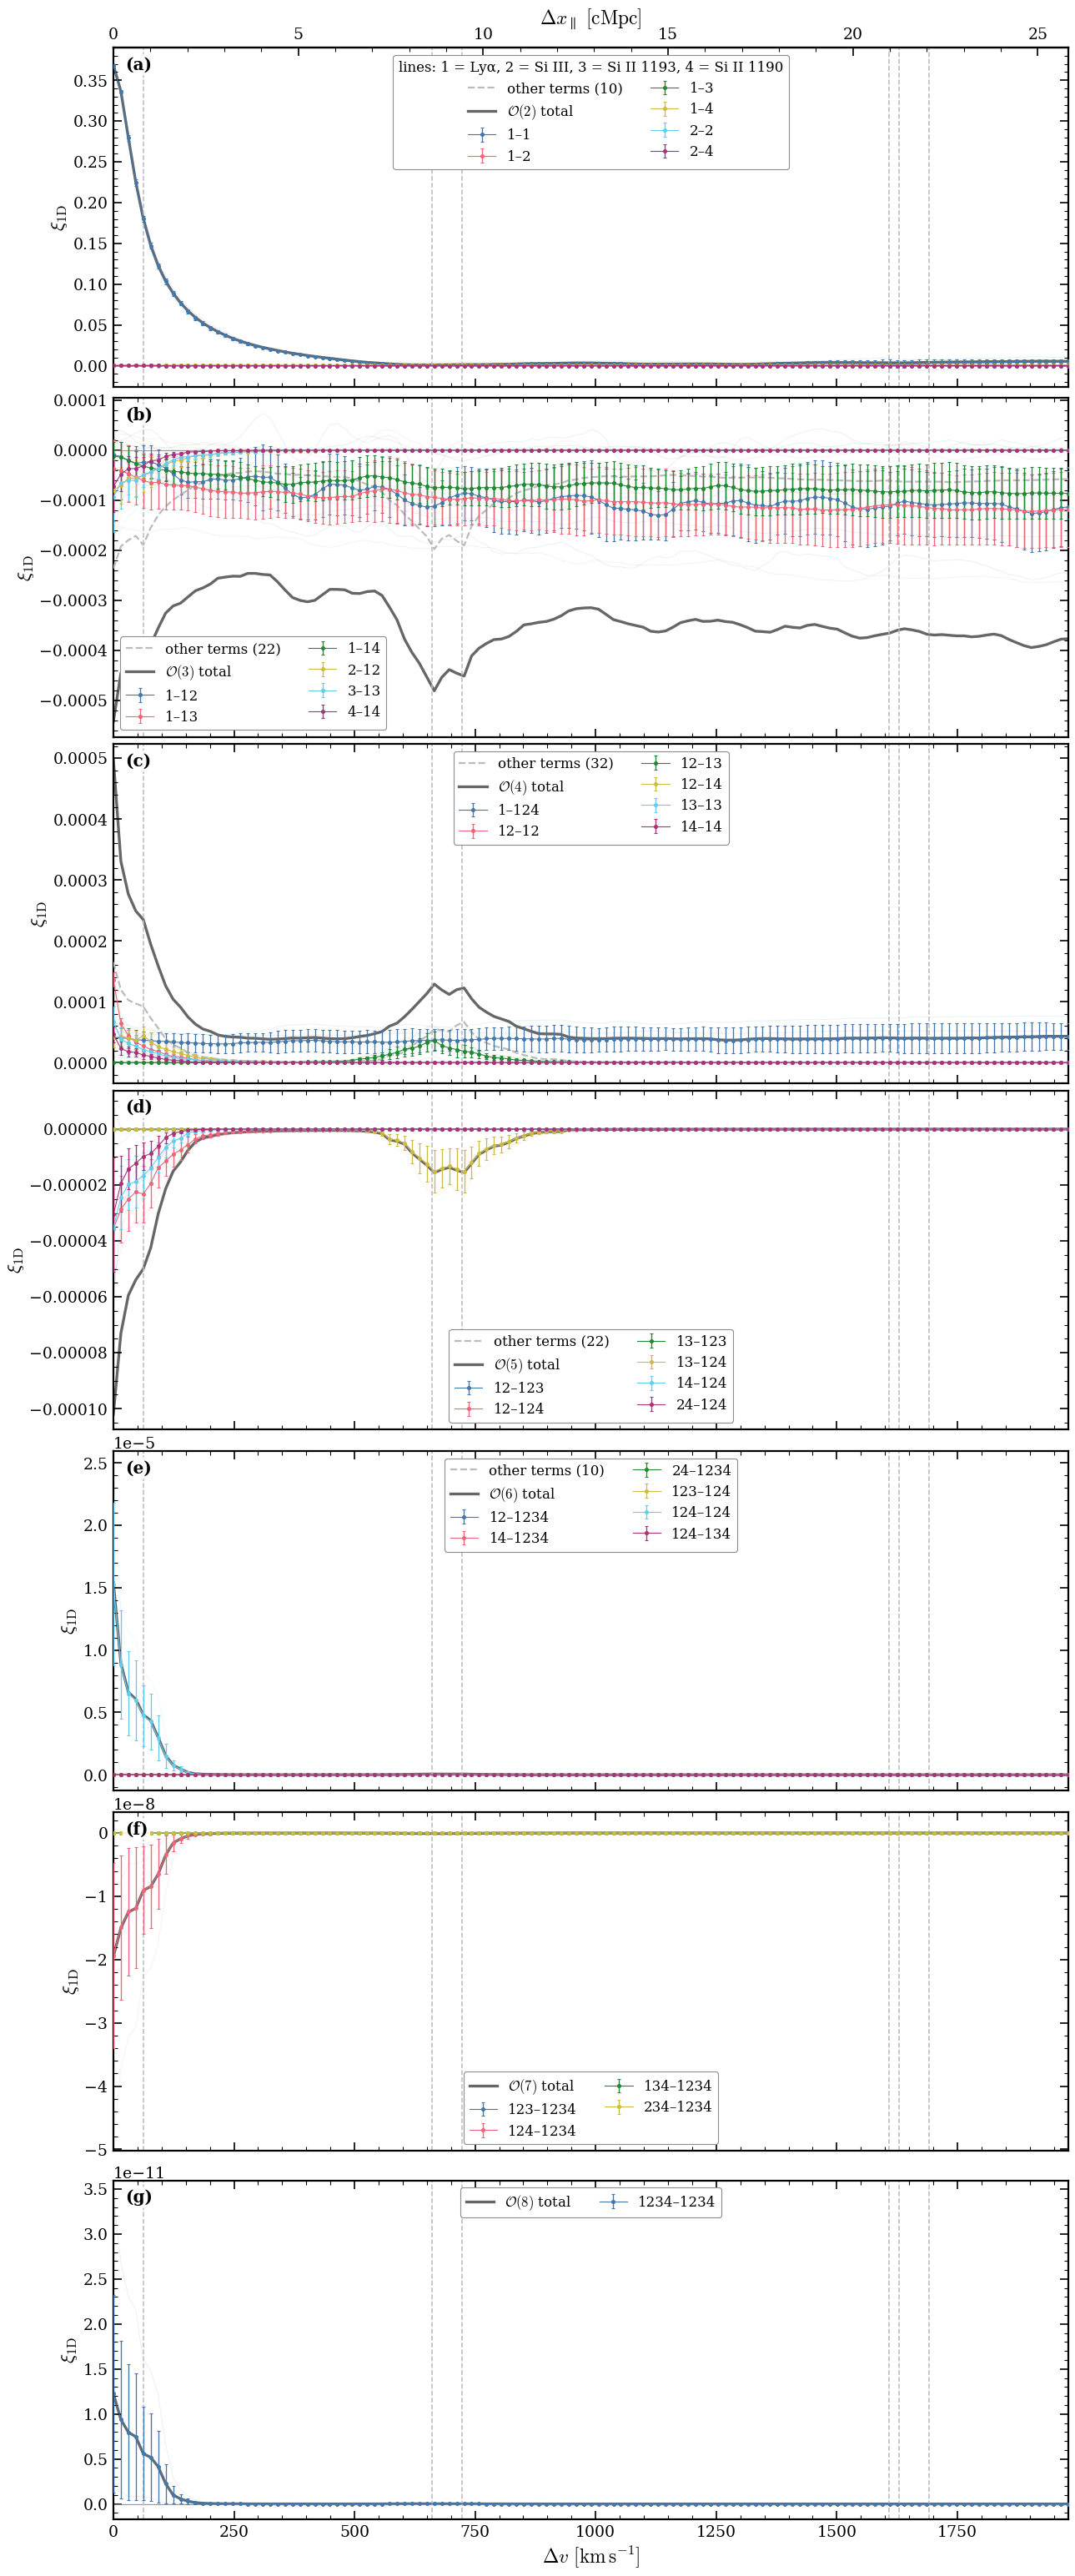

In [22]:
from skewerjax.utils.plotting import plot_p1d_terms, plot_xi1d_terms
fig, axs = plot_p1d_terms(FLUX_ORDERS, k_edges=K_EDGES_1D, k_limits=K_LIMITS_1D, kms_per_cMpc=u, line_ids=LINE_IDS)  # the largest terms of each order
add_panel_letters(axs)
plt.show()
fig, axs = plot_xi1d_terms(FLUX_ORDERS, delta_v_list=dv_lines, kms_per_cMpc=u, line_ids=LINE_IDS)  # the separation, folded: dashed
add_panel_letters(axs)
plt.show()